In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


DATASET LOADING

In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/legal_text_classification.csv")
df.head(7)

,case_id,case_outcome,case_title,case_text
0,Case1,cited,Alpine Hardwood (Aust) Pty Ltd v Hardys Pty Lt...,Ordinarily that discretion will be exercised s...
1,Case2,cited,Black v Lipovac [1998] FCA 699 ; (1998) 217 AL...,The general principles governing the exercise ...
2,Case3,cited,Colgate Palmolive Co v Cussons Pty Ltd (1993) ...,Ordinarily that discretion will be exercised s...
3,Case4,cited,Dais Studio Pty Ltd v Bullett Creative Pty Ltd...,The general principles governing the exercise ...
4,Case5,cited,Dr Martens Australia Pty Ltd v Figgins Holding...,The preceding general principles inform the ex...
5,Case6,cited,GEC Marconi Systems Pty Ltd v BHP Information ...,I accept that the making of a rolled up offer ...
6,Case7,cited,John S Hayes &amp; Associates Pty Ltd v Kimber...,The preceding general principles inform the ex...


**EDA**

In [ ]:

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())

print("\nStatistical summary:")
display(df.describe(include="all"))

Number of rows: 24985
Number of columns: 4

Column names:
['case_id', 'case_outcome', 'case_title', 'case_text']

Data types:
case_id         object
case_outcome    object
case_title      object
case_text       object
dtype: object

First 5 rows:


,case_id,case_outcome,case_title,case_text
0,Case1,cited,Alpine Hardwood (Aust) Pty Ltd v Hardys Pty Lt...,Ordinarily that discretion will be exercised s...
1,Case2,cited,Black v Lipovac [1998] FCA 699 ; (1998) 217 AL...,The general principles governing the exercise ...
2,Case3,cited,Colgate Palmolive Co v Cussons Pty Ltd (1993) ...,Ordinarily that discretion will be exercised s...
3,Case4,cited,Dais Studio Pty Ltd v Bullett Creative Pty Ltd...,The general principles governing the exercise ...
4,Case5,cited,Dr Martens Australia Pty Ltd v Figgins Holding...,The preceding general principles inform the ex...



Statistical summary:


,case_id,case_outcome,case_title,case_text
count,24985,24985,24985,24809
unique,24985,10,18581,17920
top,Case25207,cited,Minister for Immigration and Ethnic Affairs v ...,submitted that this Court should hold that the...
freq,1,12219,70,42


In [ ]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values[missing_values > 0])


missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing value percentage:")
print(missing_percentage[missing_percentage > 0])

Missing values in each column:
case_text    176
dtype: int64

Missing value percentage:
case_text    0.704423
dtype: float64


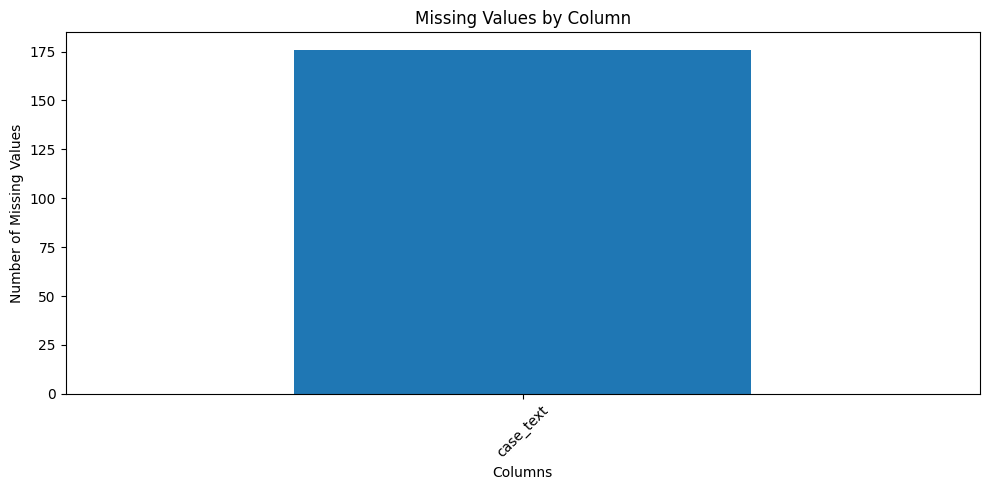

In [ ]:
import matplotlib.pyplot as plt

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

plt.figure(figsize=(10, 5))
missing.plot(kind="bar")
plt.title("Missing Values by Column")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24985 entries, 0 to 24984
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   case_id       24985 non-null  object
 1   case_outcome  24985 non-null  object
 2   case_title    24985 non-null  object
 3   case_text     24809 non-null  object
dtypes: object(4)
memory usage: 780.9+ KB


In [ ]:
df.shape

(24985, 4)

In [ ]:
print(df["case_outcome"].unique())

['cited' 'applied' 'followed' 'referred to' 'related' 'considered'
 'discussed' 'distinguished' 'affirmed' 'approved']


In [ ]:
print(df["case_outcome"].value_counts())

case_outcome
cited            12219
referred to       4384
applied           2448
followed          2256
considered        1712
discussed         1024
distinguished      608
related            113
affirmed           113
approved           108
Name: count, dtype: int64


In [ ]:
print(df.isnull().sum())

case_id           0
case_outcome      0
case_title        0
case_text       176
dtype: int64


In [ ]:
df = df.dropna(subset=["case_text"])

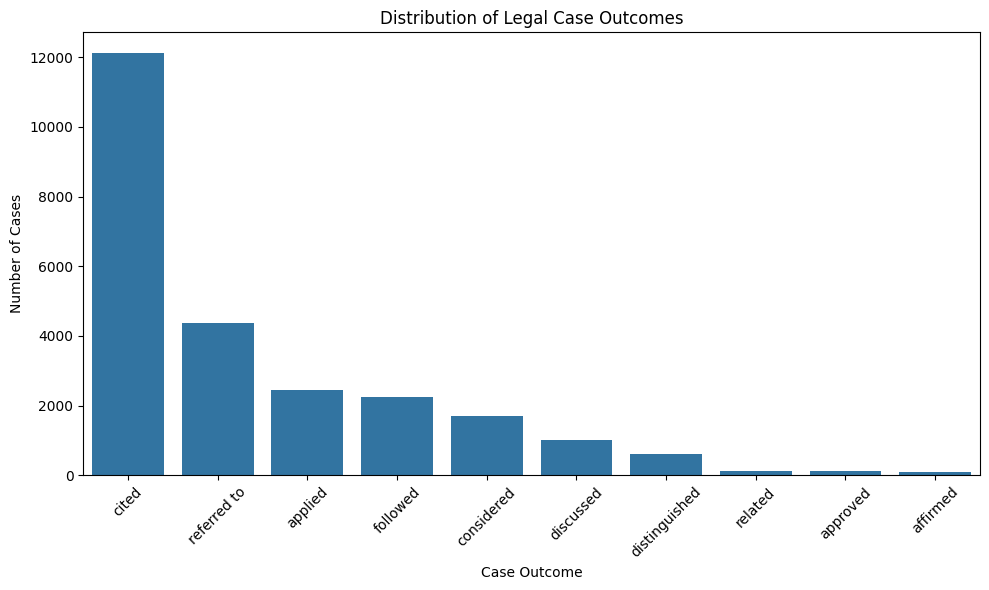

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="case_outcome",
    order=df["case_outcome"].value_counts().index
)

plt.title("Distribution of Legal Case Outcomes")
plt.xlabel("Case Outcome")
plt.ylabel("Number of Cases")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

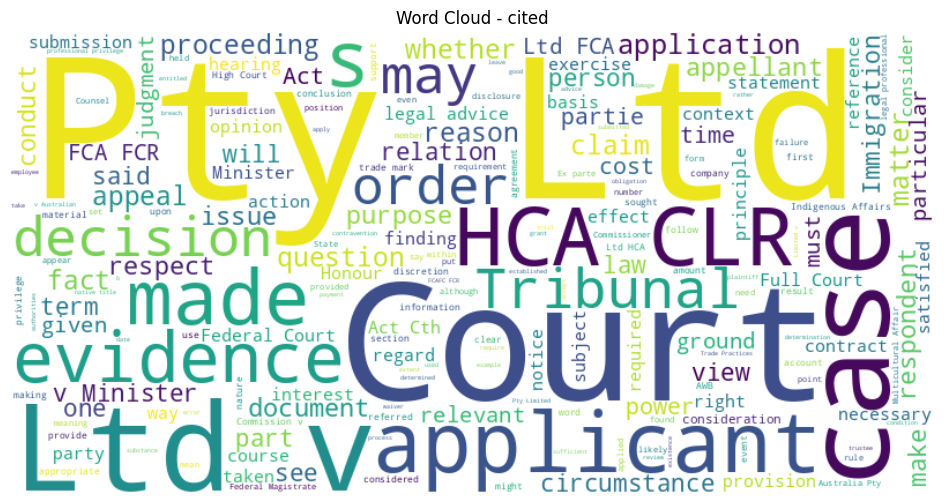

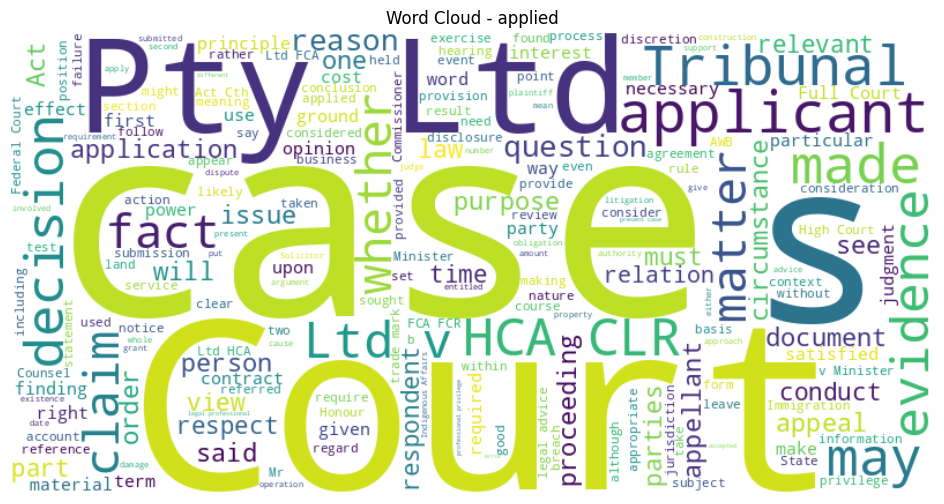

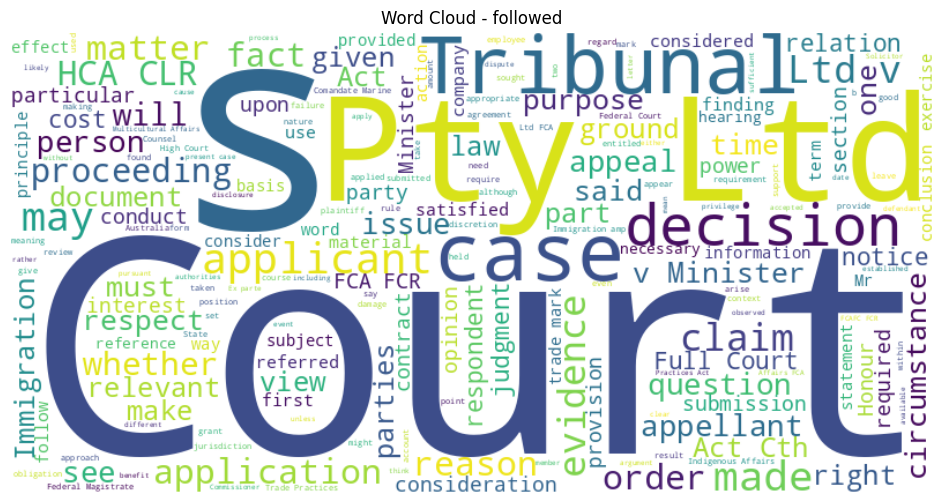

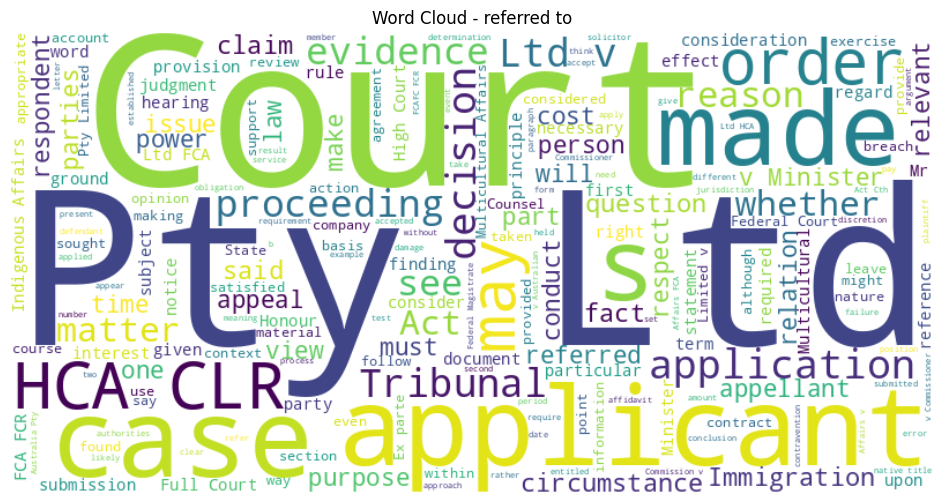

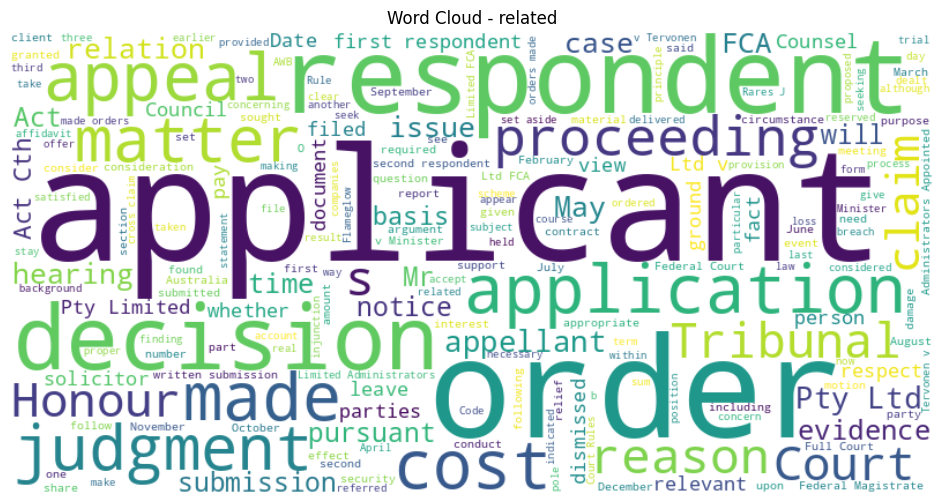

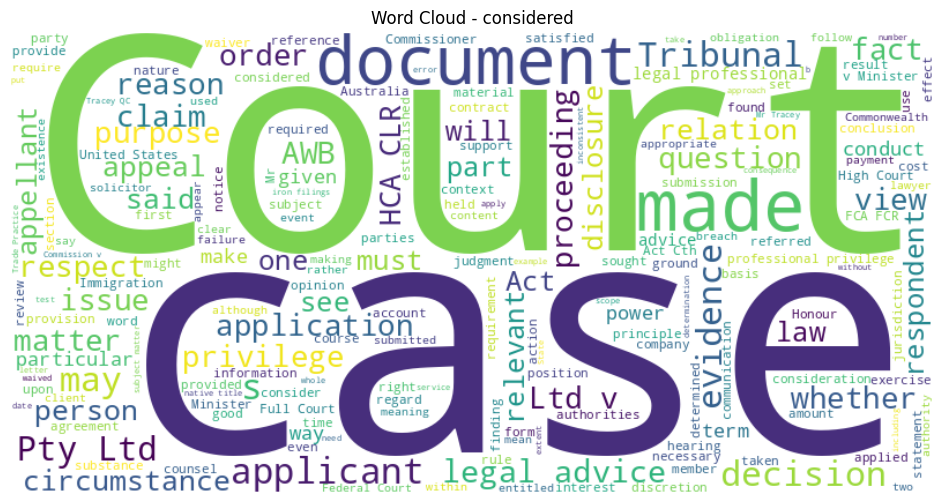

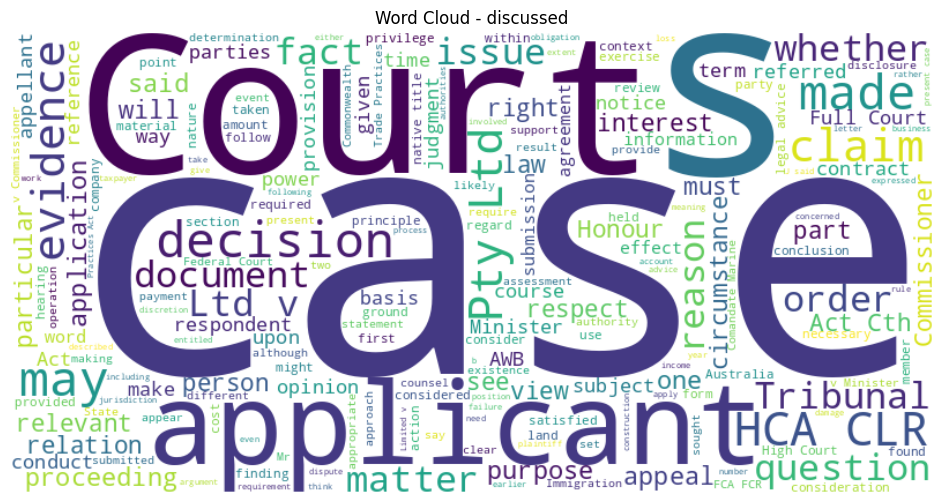

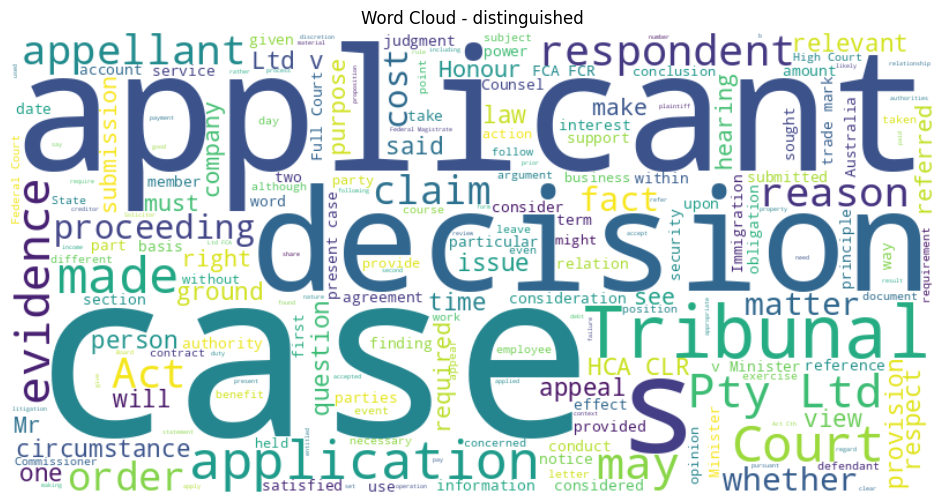

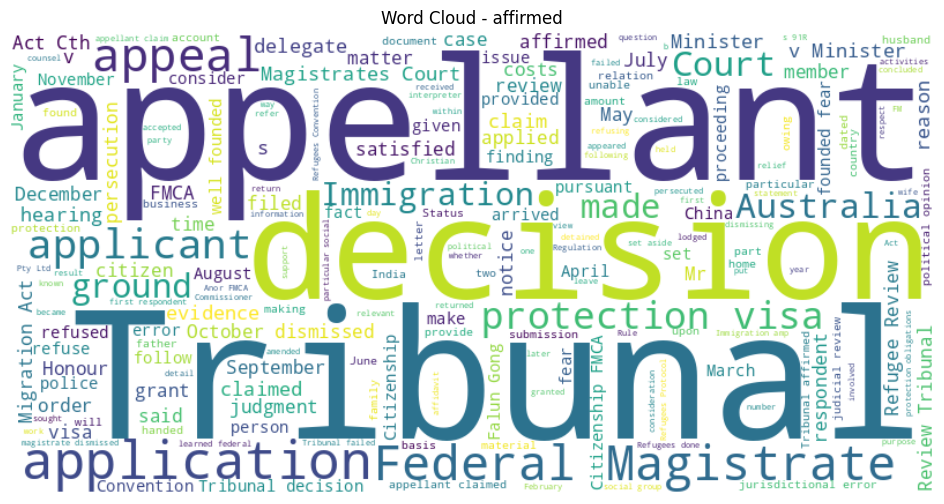

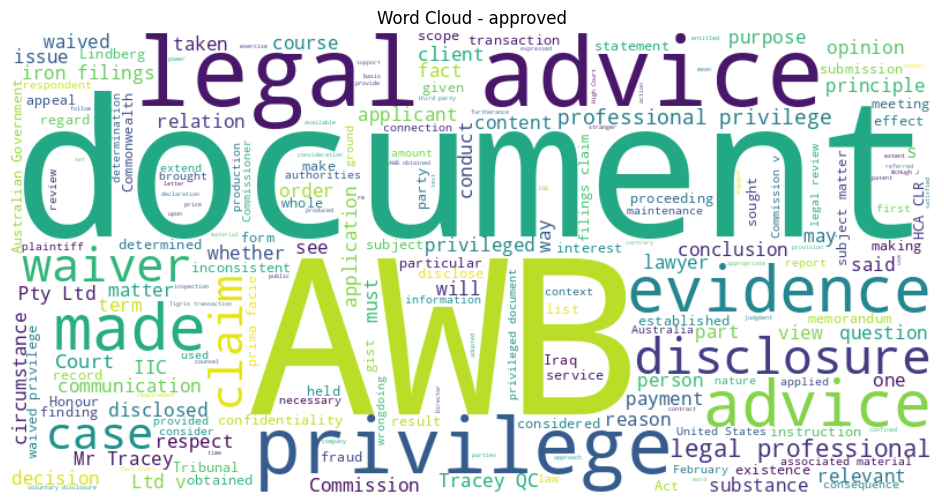

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

classes = df["case_outcome"].unique()

for category in classes:
    text = " ".join(
        df[df["case_outcome"] == category]["case_text"].astype(str)
    )

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white"
    ).generate(text)

    plt.figure(figsize=(12, 6))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud - " + category)
    plt.show()

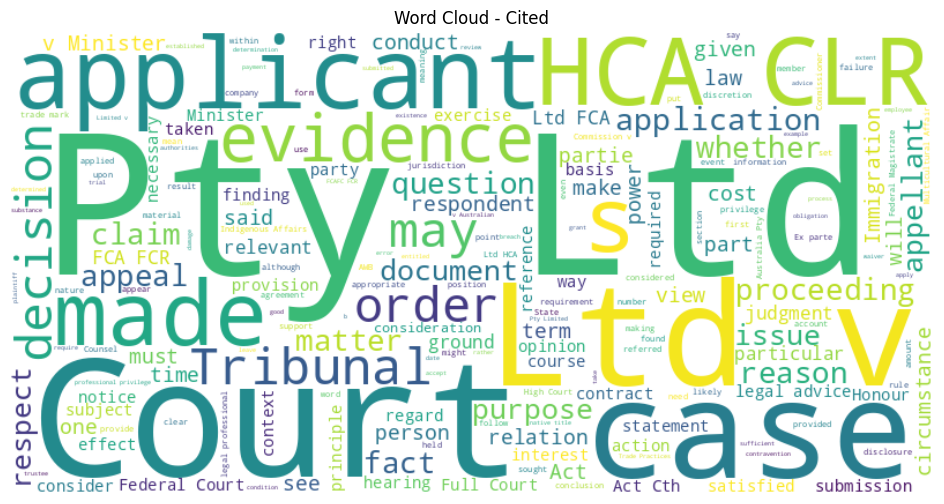

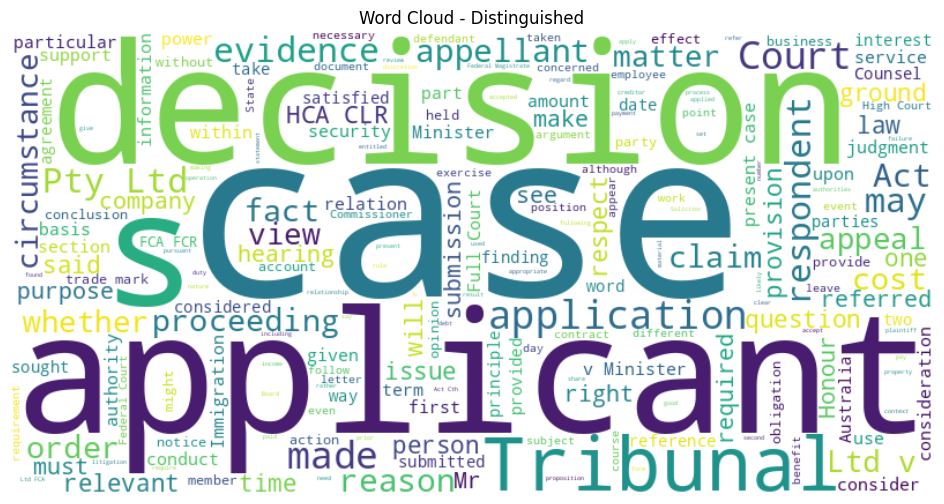

In [ ]:
from wordcloud import WordCloud

cited_text = " ".join(
    df[df["case_outcome"] == "cited"]["case_text"]
)

distinguished_text = " ".join(
    df[df["case_outcome"] == "distinguished"]["case_text"]
)
wordcloud_cited = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(cited_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud_cited, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud - Cited")
plt.show()
wordcloud_distinguished = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(distinguished_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud_distinguished, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud - Distinguished")
plt.show()

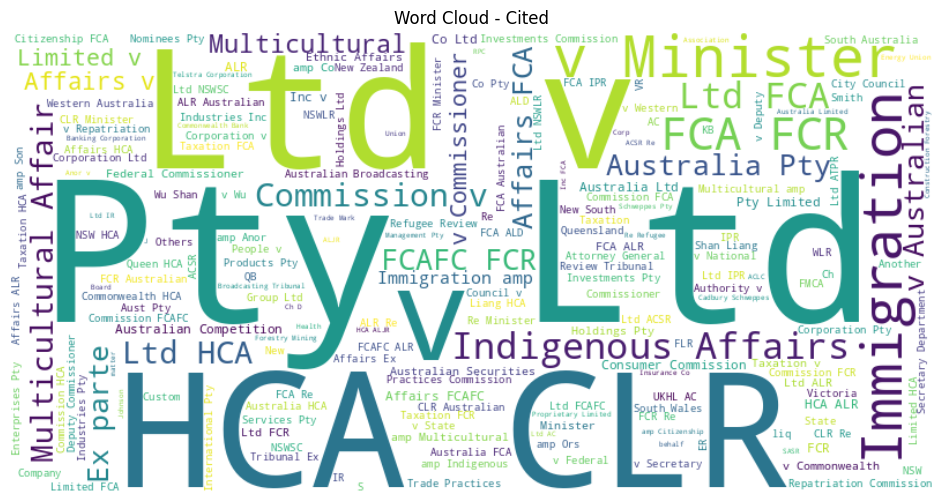

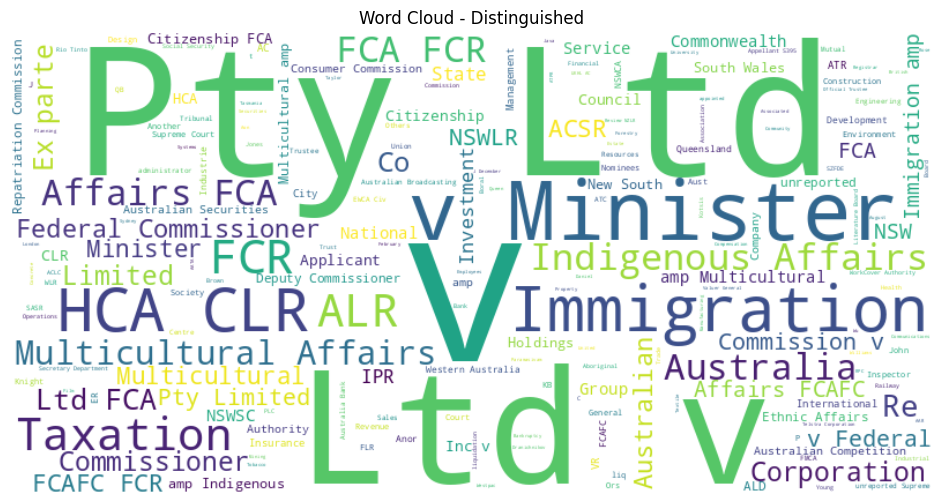

In [ ]:
from wordcloud import WordCloud

cited_text = " ".join(
    df[df["case_outcome"] == "cited"]["case_title"]
)

distinguished_text = " ".join(
    df[df["case_outcome"] == "distinguished"]["case_title"]
)
wordcloud_cited = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(cited_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud_cited, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud - Cited")
plt.show()
wordcloud_distinguished = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(distinguished_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud_distinguished, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud - Distinguished")
plt.show()

In [ ]:

df["text_length"] = df["case_text"].fillna("").apply(len)

print("Text length statistics:")
print(df["text_length"].describe())

Text length statistics:
count     24985.000000
mean       2632.266560
std        6748.704708
min           0.000000
25%         830.000000
50%        1399.000000
75%        2519.000000
max      133561.000000
Name: text_length, dtype: float64


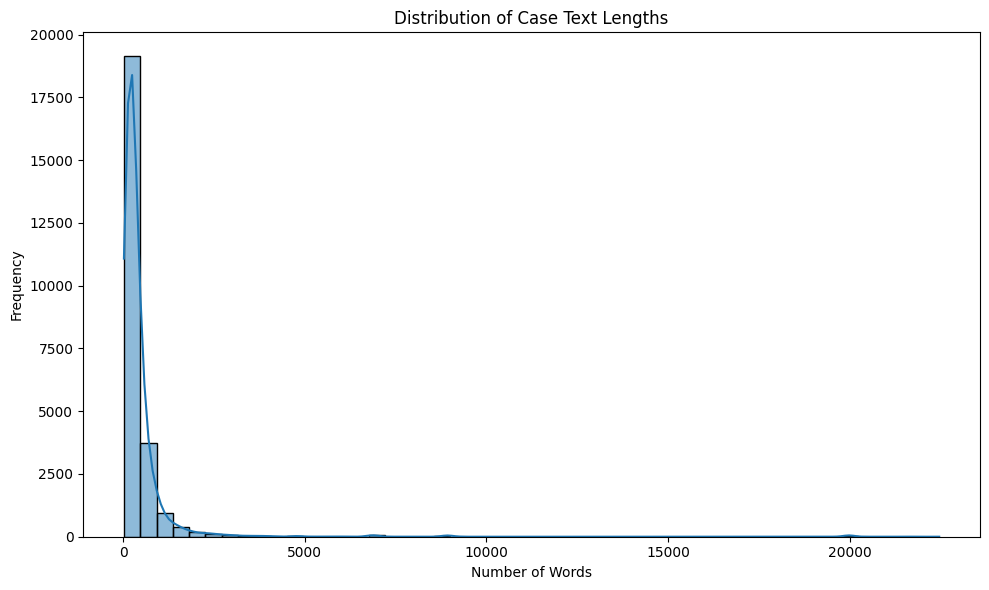

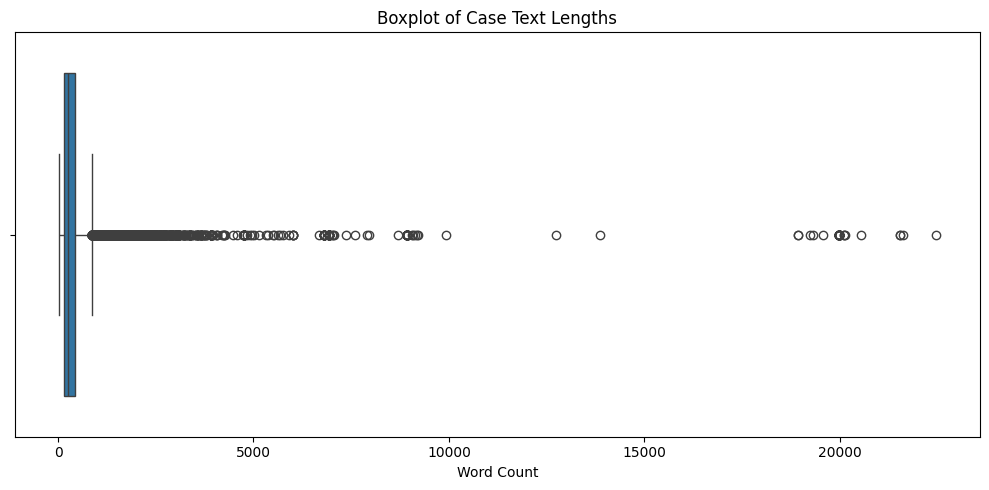

In [ ]:
df["word_count"] = df["case_text"].str.split().str.len()
plt.figure(figsize=(10, 6))

sns.histplot(df["word_count"], bins=50, kde=True)

plt.title("Distribution of Case Text Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["word_count"])

plt.title("Boxplot of Case Text Lengths")
plt.xlabel("Word Count")
plt.tight_layout()
plt.show()

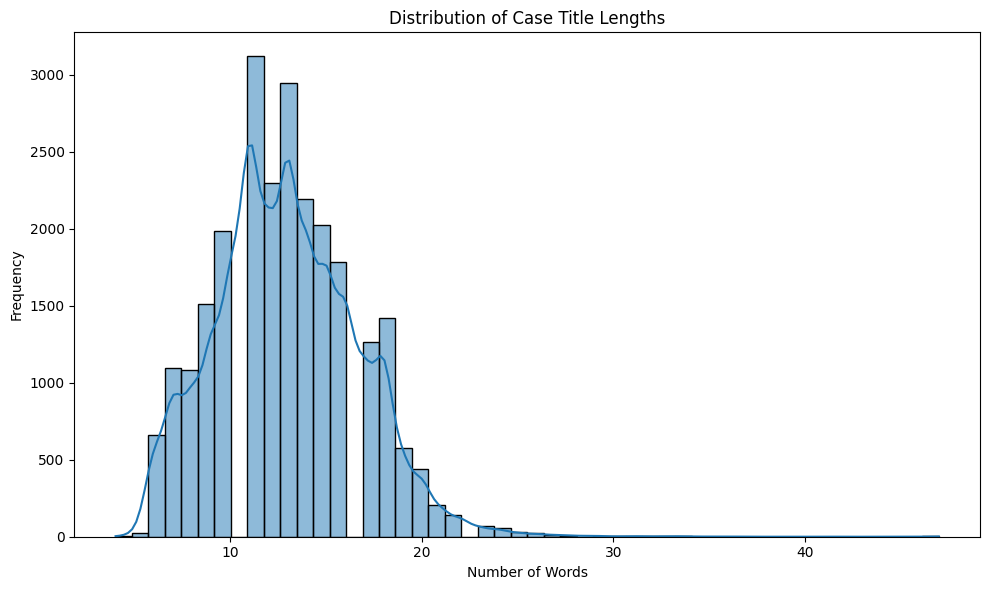

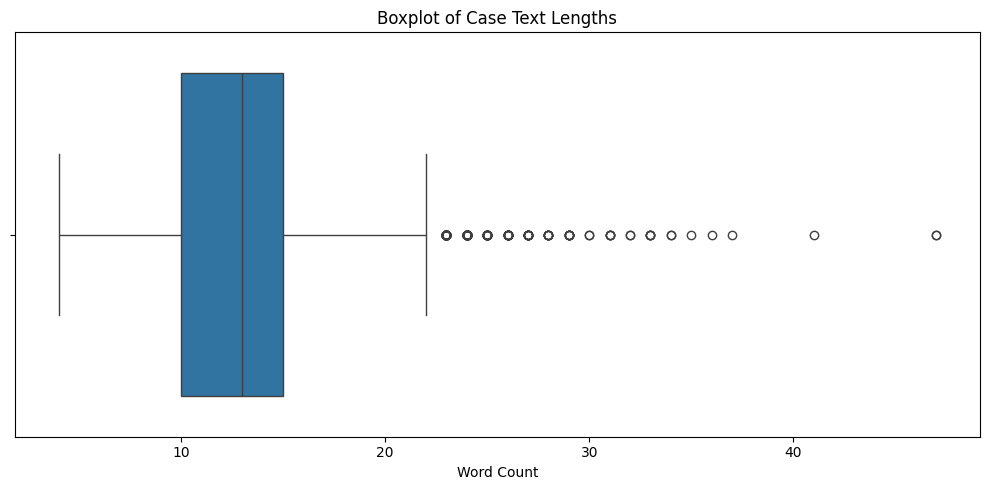

In [ ]:
df["word_count"] = df["case_title"].str.split().str.len()
plt.figure(figsize=(10, 6))

sns.histplot(df["word_count"], bins=50, kde=True)

plt.title("Distribution of Case Title Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["word_count"])

plt.title("Boxplot of Case Text Lengths")
plt.xlabel("Word Count")
plt.tight_layout()
plt.show()

PREPROCESSING

In [ ]:
df = df.dropna(
    subset=["case_outcome", "case_text"]
).copy()

print(df.shape)

(24809, 4)


In [ ]:
df["case_outcome"] = (
    df["case_outcome"]
    .astype(str)
    .str.strip()
)

df["case_title"] = (
    df["case_title"]
    .fillna("")
    .astype(str)
    .str.strip()
)

df["case_text"] = (
    df["case_text"]
    .astype(str)
    .str.strip()
)

In [ ]:
df["case_title_original"] = df["case_title"]
df["case_text_original"] = df["case_text"]

In [ ]:
import re
import unicodedata

def normalize_for_duplicate_detection(text):
    text = str(text)


    text = unicodedata.normalize("NFKC", text)


    text = text.lower()


    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [ ]:
df["title_duplicate"] = df["case_title"].apply(
    normalize_for_duplicate_detection
)

df["text_duplicate"] = df["case_text"].apply(
    normalize_for_duplicate_detection
)

In [ ]:
text_duplicates = df["text_duplicate"].duplicated(keep=False)

print(
    "Rows belonging to duplicated case texts:",
    text_duplicates.sum()
)

Rows belonging to duplicated case texts: 10839


In [ ]:
label_counts_per_text = (
    df.groupby("text_duplicate")["case_outcome"]
      .nunique()
)

conflicting_texts = label_counts_per_text[
    label_counts_per_text > 1
]

print(
    "Number of text groups with conflicting labels:",
    len(conflicting_texts)
)

Number of text groups with conflicting labels: 1014


In [ ]:
print(
    "Rows with duplicated titles:",
    (df["title_duplicate"].duplicated(keep=False)).sum()
)

Rows with duplicated titles: 9789


In [ ]:
title_label_counts = (
    df.groupby("title_duplicate")["case_outcome"]
      .nunique()
)

conflicting_titles = title_label_counts[
    title_label_counts > 1
]

print(
    "Titles associated with multiple outcomes:",
    len(conflicting_titles)
)

Titles associated with multiple outcomes: 2197


In [ ]:
df["model_text"] = (
    "TITLE: " +
    df["case_title"] +
    " TEXT: " +
    df["case_text"]
)

In [ ]:
def clean_legal_text(text):
    text = str(text)


    text = unicodedata.normalize("NFKC", text)


    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [ ]:
df["model_text"] = df["model_text"].apply(clean_legal_text)

In [ ]:
df["model_text"] = df["model_text"].str.strip()

df = df[df["model_text"].str.len() > 0].copy()

print(df.shape)

(24809, 9)


In [ ]:
df["group_id"] = pd.factorize(
    df["text_duplicate"]
)[0]

In [ ]:
X = df["model_text"]
y = df["case_outcome"]
groups = df["group_id"]

In [ ]:
case_ids = df["case_id"]

 Train/Validation/Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp, ids_train, ids_temp = train_test_split(
    X,
    y,
    case_ids,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test, ids_val, ids_test = train_test_split(
    X_temp,
    y_temp,
    ids_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

**Text Representation**


TFIDF

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [ ]:
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words=None,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.98,
    sublinear_tf=True,
    max_features=200000
)

In [ ]:
X_train_tfidf = tfidf.fit_transform(X_train)

X_val_tfidf = tfidf.transform(X_val)

X_test_tfidf = tfidf.transform(X_test)

WORD2VEC then Average

In [ ]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 81.2 MB/s eta 0:00:00


In [ ]:
from gensim.models import Word2Vec

In [ ]:
import re

In [ ]:
def tokenize_text(text):
    text = str(text).lower()
    text = re.sub(r"\s+", " ", text)
    tokens = text.split()
    return tokens

In [ ]:
train_tokens = [
    tokenize_text(text)
    for text in X_train
]

In [ ]:
word2vec_model = Word2Vec(
    sentences=train_tokens,
    vector_size=200,
    window=5,
    min_count=2,
    workers=4,
    sg=1
)

In [ ]:
val_tokens = [
    tokenize_text(text)
    for text in X_val
]

test_tokens = [
    tokenize_text(text)
    for text in X_test
]

In [ ]:
import numpy as np

def document_vector(tokens, model):
    vectors = [
        model.wv[word]
        for word in tokens
        if word in model.wv
    ]

    if not vectors:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)

In [ ]:
X_train_w2v = np.array([
    document_vector(tokens, word2vec_model)
    for tokens in train_tokens
])

X_val_w2v = np.array([
    document_vector(tokens, word2vec_model)
    for tokens in val_tokens
])

X_test_w2v = np.array([
    document_vector(tokens, word2vec_model)
    for tokens in test_tokens
])

In [ ]:
print(X_train_w2v.shape)
print(X_val_w2v.shape)
print(X_test_w2v.shape)

(19847, 200)
(2481, 200)
(2481, 200)


**ML MODELS**

In [ ]:
#LOGISTOC REGRESSION
from sklearn.linear_model import LogisticRegression

In [ ]:
lr_1 = LogisticRegression(
    C=2.0,
    max_iter=2000,
    solver="saga",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

lr_1.fit(X_train_tfidf, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


LogisticRegression(C=2.0, class_weight='balanced', max_iter=2000, n_jobs=-1,
                   random_state=42, solver='saga')

In [ ]:
lr_2 = LogisticRegression(
    C=2.5,
    max_iter=1000,
    solver="saga",
    class_weight=None,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

lr_2.fit(X_train_tfidf, y_train)

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.


convergence after 163 epochs took 151 seconds


LogisticRegression(C=2.5, max_iter=1000, n_jobs=-1, random_state=42,
                   solver='saga', verbose=1)

In [ ]:
lr_3 = LogisticRegression(
    C=10.0,
    max_iter=500,
    solver="saga",
    class_weight=None,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

lr_3.fit(X_train_tfidf, y_train)

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.


convergence after 263 epochs took 206 seconds


LogisticRegression(C=10.0, max_iter=500, n_jobs=-1, random_state=42,
                   solver='saga', verbose=1)

In [ ]:
#REPORTS OF LR

In [ ]:
from sklearn.metrics import f1_score

y_val_pred_lr1 = lr_1.predict(X_val_tfidf)
y_val_pred_lr2 = lr_2.predict(X_val_tfidf)
y_val_pred_lr3 = lr_3.predict(X_val_tfidf)

f1_lr1 = f1_score(y_val, y_val_pred_lr1, average="macro")
f1_lr2 = f1_score(y_val, y_val_pred_lr2, average="macro")
f1_lr3 = f1_score(y_val, y_val_pred_lr3, average="macro")

print("LR 1 (C=0.1):", f1_lr1)
print("LR 2 (C=1.0):", f1_lr2)
print("LR 3 (C=10.0):", f1_lr3)

LR 1 (C=0.1): 0.3618013813091919
LR 2 (C=1.0): 0.35218035706416273
LR 3 (C=10.0): 0.42129845005920785


In [ ]:
best_lr = lr_3

In [ ]:
y_test_pred_lr = best_lr.predict(X_test_tfidf)

In [ ]:
from sklearn.metrics import accuracy_score, f1_score

accuracy_lr = accuracy_score(y_test, y_test_pred_lr)
f1_lr = f1_score(y_test, y_test_pred_lr, average="macro")

print("Logistic Regression Test Accuracy:", accuracy_lr)
print("Logistic Regression Test Macro F1:", f1_lr)

Logistic Regression Test Accuracy: 0.6251511487303507
Logistic Regression Test Macro F1: 0.42758948419818477


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_test_pred_lr))

               precision    recall  f1-score   support

     affirmed       0.62      0.45      0.53        11
      applied       0.44      0.29      0.35       244
     approved       1.00      0.10      0.18        10
        cited       0.66      0.88      0.76      1211
   considered       0.53      0.31      0.39       170
    discussed       0.52      0.25      0.33       102
distinguished       0.62      0.27      0.37        60
     followed       0.52      0.30      0.38       225
  referred to       0.63      0.55      0.58       437
      related       0.75      0.27      0.40        11

     accuracy                           0.63      2481
    macro avg       0.63      0.37      0.43      2481
 weighted avg       0.61      0.63      0.60      2481



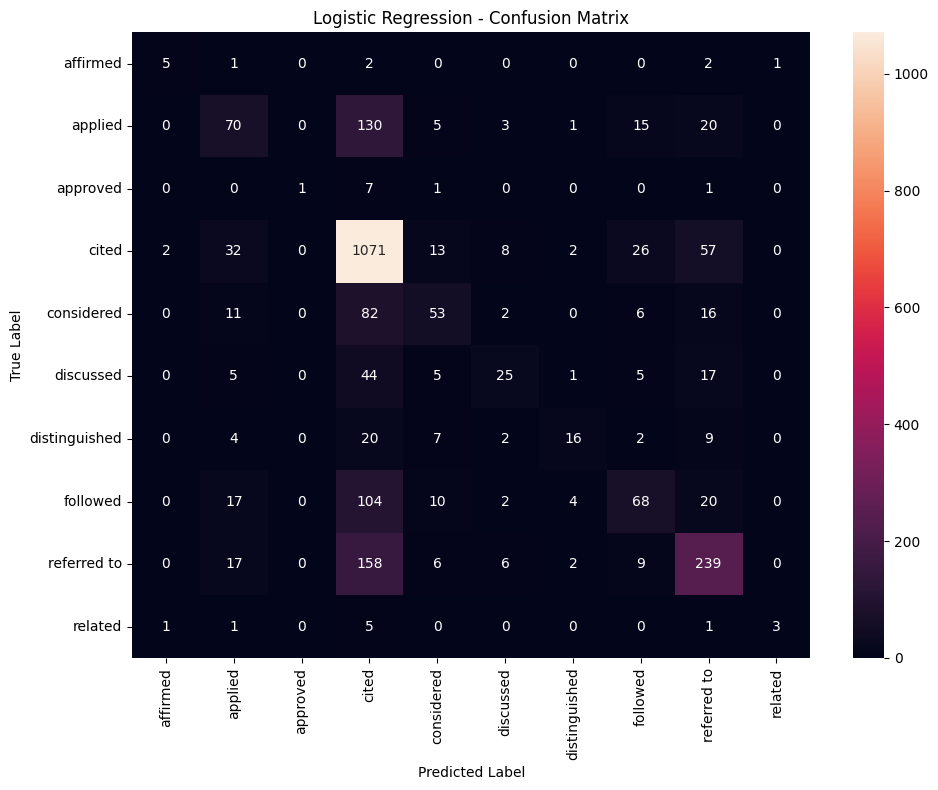

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_test_pred_lr)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=sorted(y_test.unique()),
    yticklabels=sorted(y_test.unique())
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

In [ ]:
#NAIVE BAYES

In [ ]:
from sklearn.naive_bayes import MultinomialNB

nb_1 = MultinomialNB(
    alpha=0.01
)

nb_1.fit(X_train_tfidf, y_train)

MultinomialNB(alpha=0.01)

In [ ]:
nb_2 = MultinomialNB(
    alpha=0.1
)

nb_2.fit(X_train_tfidf, y_train)

MultinomialNB(alpha=0.1)

In [ ]:
nb_3 = MultinomialNB(
    alpha=1.0
)

nb_3.fit(X_train_tfidf, y_train)

MultinomialNB()

In [ ]:
from sklearn.metrics import accuracy_score, f1_score

y_val_pred_nb1 = nb_1.predict(X_val_tfidf)
y_val_pred_nb2 = nb_2.predict(X_val_tfidf)
y_val_pred_nb3 = nb_3.predict(X_val_tfidf)

nb1_accuracy = accuracy_score(y_val, y_val_pred_nb1)
nb1_f1 = f1_score(y_val, y_val_pred_nb1, average="macro")

nb2_accuracy = accuracy_score(y_val, y_val_pred_nb2)
nb2_f1 = f1_score(y_val, y_val_pred_nb2, average="macro")

nb3_accuracy = accuracy_score(y_val, y_val_pred_nb3)
nb3_f1 = f1_score(y_val, y_val_pred_nb3, average="macro")

print("NB 1 (alpha=0.01)")
print("Validation Accuracy:", nb1_accuracy)
print("Validation Macro F1:", nb1_f1)

print("\nNB 2 (alpha=0.1)")
print("Validation Accuracy:", nb2_accuracy)
print("Validation Macro F1:", nb2_f1)

print("\nNB 3 (alpha=1.0)")
print("Validation Accuracy:", nb3_accuracy)
print("Validation Macro F1:", nb3_f1)

NB 1 (alpha=0.01)
Validation Accuracy: 0.5755743651753326
Validation Macro F1: 0.3863337488215669

NB 2 (alpha=0.1)
Validation Accuracy: 0.5683192261185006
Validation Macro F1: 0.22664852962797707

NB 3 (alpha=1.0)
Validation Accuracy: 0.4917372027408303
Validation Macro F1: 0.06980655120550847


In [ ]:
nb_tuning_results = pd.DataFrame({
    "Configuration": ["alpha=0.01", "alpha=0.1", "alpha=1.0"],
    "Validation Accuracy": [
        nb1_accuracy,
        nb2_accuracy,
        nb3_accuracy
    ],
    "Validation Macro F1": [
        nb1_f1,
        nb2_f1,
        nb3_f1
    ]
})

nb_tuning_results

,Configuration,Validation Accuracy,Validation Macro F1
0,alpha=0.01,0.575574,0.386334
1,alpha=0.1,0.568319,0.226649
2,alpha=1.0,0.491737,0.069807


In [ ]:
best_nb = nb_1

In [ ]:
y_test_pred_nb = best_nb.predict(X_test_tfidf)

In [ ]:
from sklearn.metrics import accuracy_score

nb_test_accuracy = accuracy_score(y_test, y_test_pred_nb)

print("Naive Bayes Test Accuracy:", nb_test_accuracy)

Naive Bayes Test Accuracy: 0.5703345425231762


In [ ]:
from sklearn.metrics import f1_score

nb_test_f1 = f1_score(
    y_test,
    y_test_pred_nb,
    average="macro"
)

print("Naive Bayes Test Macro F1:", nb_test_f1)

Naive Bayes Test Macro F1: 0.39527438478955346


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_test_pred_nb
))

               precision    recall  f1-score   support

     affirmed       0.44      0.64      0.52        11
      applied       0.35      0.29      0.32       244
     approved       0.11      0.20      0.14        10
        cited       0.65      0.77      0.70      1211
   considered       0.41      0.30      0.35       170
    discussed       0.34      0.36      0.35       102
distinguished       0.38      0.25      0.30        60
     followed       0.37      0.31      0.33       225
  referred to       0.66      0.53      0.59       437
      related       0.50      0.27      0.35        11

     accuracy                           0.57      2481
    macro avg       0.42      0.39      0.40      2481
 weighted avg       0.56      0.57      0.56      2481



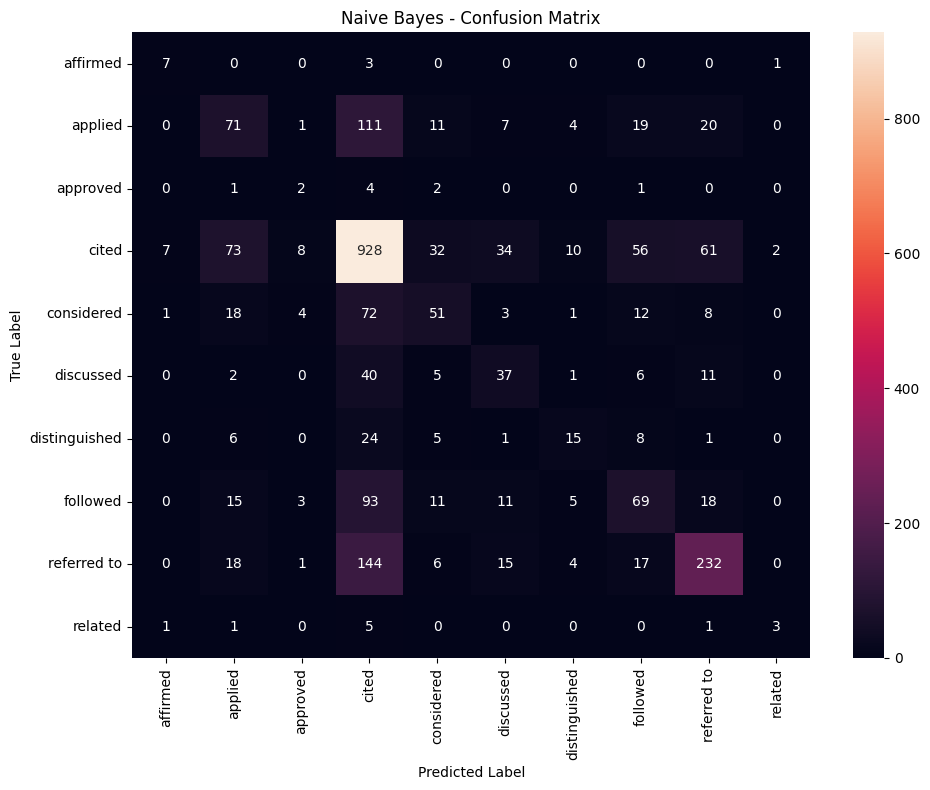

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_nb = confusion_matrix(y_test, y_test_pred_nb)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    xticklabels=sorted(y_test.unique()),
    yticklabels=sorted(y_test.unique())
)

plt.title("Naive Bayes - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

In [ ]:
#RANDOM FOREST

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_1 = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    min_samples_split=2,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

rf_1.fit(X_train_tfidf, y_train)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [ ]:
rf_2 = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_2.fit(X_train_tfidf, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=300, n_jobs=-1,
                       random_state=42)

In [ ]:
rf_3 = RandomForestClassifier(
    n_estimators=300,
    max_depth=30,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_3.fit(X_train_tfidf, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=30,
                       min_samples_leaf=2, min_samples_split=5,
                       n_estimators=300, n_jobs=-1, random_state=42)

In [ ]:
from sklearn.metrics import accuracy_score, f1_score

y_val_pred_rf1 = rf_1.predict(X_val_tfidf)
y_val_pred_rf2 = rf_2.predict(X_val_tfidf)
y_val_pred_rf3 = rf_3.predict(X_val_tfidf)

rf1_accuracy = accuracy_score(y_val, y_val_pred_rf1)
rf1_f1 = f1_score(y_val, y_val_pred_rf1, average="macro")

rf2_accuracy = accuracy_score(y_val, y_val_pred_rf2)
rf2_f1 = f1_score(y_val, y_val_pred_rf2, average="macro")

rf3_accuracy = accuracy_score(y_val, y_val_pred_rf3)
rf3_f1 = f1_score(y_val, y_val_pred_rf3, average="macro")

print("RF 1")
print("Validation Accuracy:", rf1_accuracy)
print("Validation Macro F1:", rf1_f1)

print("\nRF 2")
print("Validation Accuracy:", rf2_accuracy)
print("Validation Macro F1:", rf2_f1)

print("\nRF 3")
print("Validation Accuracy:", rf3_accuracy)
print("Validation Macro F1:", rf3_f1)

RF 1
Validation Accuracy: 0.5856509471987102
Validation Macro F1: 0.2754548369205455

RF 2
Validation Accuracy: 0.5796049979846836
Validation Macro F1: 0.3026717988742468

RF 3
Validation Accuracy: 0.4921402660217654
Validation Macro F1: 0.32908988167372205


In [ ]:
rf_tuning_results = pd.DataFrame({
    "Configuration": [
        "100 trees, depth=None, min_split=2",
        "200 trees, depth=20, min_split=2",
        "300 trees, depth=30, min_split=5"
    ],
    "Validation Accuracy": [
        rf1_accuracy,
        rf2_accuracy,
        rf3_accuracy
    ],
    "Validation Macro F1": [
        rf1_f1,
        rf2_f1,
        rf3_f1
    ]
})

rf_tuning_results

,Configuration,Validation Accuracy,Validation Macro F1
0,"100 trees, depth=None, min_split=2",0.585651,0.275455
1,"200 trees, depth=20, min_split=2",0.579605,0.302672
2,"300 trees, depth=30, min_split=5",0.492140,0.329090


In [ ]:
best_rf = rf_1

In [ ]:
y_test_pred_rf = best_rf.predict(X_test_tfidf)

In [ ]:
rf_test_accuracy = accuracy_score(y_test, y_test_pred_rf)

print("Random Forest Test Accuracy:", rf_test_accuracy)

Random Forest Test Accuracy: 0.5727529222087868


In [ ]:
rf_test_f1 = f1_score(
    y_test,
    y_test_pred_rf,
    average="macro"
)

print("Random Forest Test Macro F1:", rf_test_f1)

Random Forest Test Macro F1: 0.29262208638762366


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_test_pred_rf
))

               precision    recall  f1-score   support

     affirmed       0.67      0.18      0.29        11
      applied       0.50      0.13      0.21       244
     approved       0.50      0.10      0.17        10
        cited       0.55      0.95      0.70      1211
   considered       0.64      0.17      0.27       170
    discussed       0.32      0.06      0.10       102
distinguished       0.82      0.15      0.25        60
     followed       0.58      0.20      0.30       225
  referred to       0.82      0.34      0.48       437
      related       1.00      0.09      0.17        11

     accuracy                           0.57      2481
    macro avg       0.64      0.24      0.29      2481
 weighted avg       0.60      0.57      0.50      2481



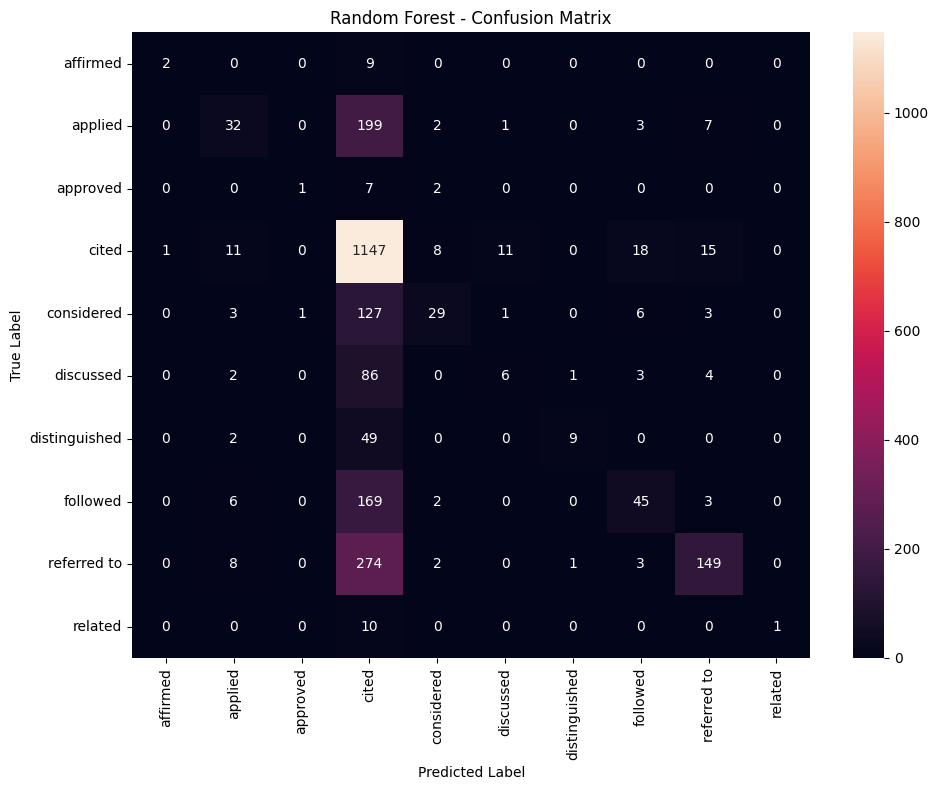

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_rf = confusion_matrix(y_test, y_test_pred_rf)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    xticklabels=sorted(y_test.unique()),
    yticklabels=sorted(y_test.unique())
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

**NN MODELS**

In [ ]:
#SIMPLE RNN PROCESSING

In [ ]:
import numpy as np
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
tokenizer = Tokenizer(
    num_words=None,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

In [ ]:
vocab_size = len(tokenizer.word_index) + 1

print("Vocabulary size:", vocab_size)

Vocabulary size: 51487


In [ ]:
X_train_seq = tokenizer.texts_to_sequences(X_train)

X_val_seq = tokenizer.texts_to_sequences(X_val)

X_test_seq = tokenizer.texts_to_sequences(X_test)

In [ ]:
sequence_lengths = [
    len(seq)
    for seq in X_train_seq
]

print("Maximum length:", max(sequence_lengths))
print("Average length:", np.mean(sequence_lengths))
print("Median length:", np.median(sequence_lengths))

Maximum length: 21741
Average length: 471.7848541341261
Median length: 257.0


In [ ]:
MAX_LEN = 600

X_train_seq = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_val_seq = pad_sequences(
    X_val_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_seq = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

In [ ]:
print(X_train_seq.shape)
print(X_val_seq.shape)
print(X_test_seq.shape)

(19847, 600)
(2481, 600)
(2481, 600)


In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)
y_test_encoded = label_encoder.transform(y_test)

num_classes = len(label_encoder.classes_)

In [ ]:
num_classes = len(label_encoder.classes_)

print("Number of classes:", num_classes)
print("Classes:", label_encoder.classes_)

Number of classes: 10
Classes: ['affirmed' 'applied' 'approved' 'cited' 'considered' 'discussed'
 'distinguished' 'followed' 'referred to' 'related']


In [ ]:
import numpy as np

embedding_dim = 200

embedding_matrix = np.zeros(
    (vocab_size, embedding_dim),
    dtype=np.float32
)

for word, index in tokenizer.word_index.items():

    if index >= vocab_size:
        continue

    if word in word2vec_model.wv:
        embedding_matrix[index] = word2vec_model.wv[word]

In [ ]:
print("Embedding dimension:", embedding_dim)
print("Embedding matrix shape:", embedding_matrix.shape)
print("Word2Vec vector shape:", word2vec_model.wv["court"].shape)

Embedding dimension: 200
Embedding matrix shape: (51487, 200)
Word2Vec vector shape: (200,)


In [ ]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

SIMPLERNN CODES

In [ ]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

rnn_1 = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=True
    ),

    SimpleRNN(128),
    Dropout(0.4),

    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(64, activation="relu"),
    Dropout(0.2),

    Dense(num_classes, activation="softmax")
])

rnn_1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping_rnn_1 = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_rnn_1 = rnn_1.fit(
    X_train_seq,
    y_train_encoded,
    validation_data=(X_val_seq, y_val_encoded),
    epochs=15,
    batch_size=64,
    callbacks=[early_stopping_rnn_1]
)

Epoch 1/15
311/311 ━━━━━━━━━━━━━━━━━━━━ 27s 71ms/step - accuracy: 0.4714 - loss: 1.6671 - val_accuracy: 0.4881 - val_loss: 1.5892
Epoch 2/15
311/311 ━━━━━━━━━━━━━━━━━━━━ 17s 55ms/step - accuracy: 0.4876 - loss: 1.6025 - val_accuracy: 0.4881 - val_loss: 1.5637
Epoch 3/15
311/311 ━━━━━━━━━━━━━━━━━━━━ 22s 61ms/step - accuracy: 0.4848 - loss: 1.6055 - val_accuracy: 0.4881 - val_loss: 1.6170
Epoch 4/15
311/311 ━━━━━━━━━━━━━━━━━━━━ 18s 57ms/step - accuracy: 0.4880 - loss: 1.6126 - val_accuracy: 0.4881 - val_loss: 1.6056
Epoch 5/15
311/311 ━━━━━━━━━━━━━━━━━━━━ 21s 59ms/step - accuracy: 0.4881 - loss: 1.6091 - val_accuracy: 0.4881 - val_loss: 1.6534


In [ ]:
rnn_2 = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=True
    ),

    SimpleRNN(256),
    Dropout(0.4),

    Dense(256, activation="relu"),
    Dropout(0.35),

    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(64, activation="relu"),
    Dropout(0.2),

    Dense(num_classes, activation="softmax")
])

rnn_2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping_rnn_2 = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

history_rnn_2 = rnn_2.fit(
    X_train_seq,
    y_train_encoded,
    validation_data=(X_val_seq, y_val_encoded),
    epochs=25,
    batch_size=32,
    callbacks=[early_stopping_rnn_2]
)

Epoch 1/25
621/621 ━━━━━━━━━━━━━━━━━━━━ 45s 63ms/step - accuracy: 0.4619 - loss: 1.6934 - val_accuracy: 0.4881 - val_loss: 1.6066
Epoch 2/25
621/621 ━━━━━━━━━━━━━━━━━━━━ 35s 56ms/step - accuracy: 0.4862 - loss: 1.6296 - val_accuracy: 0.4881 - val_loss: 1.5845
Epoch 3/25
621/621 ━━━━━━━━━━━━━━━━━━━━ 35s 56ms/step - accuracy: 0.4879 - loss: 1.6073 - val_accuracy: 0.4881 - val_loss: 1.6075
Epoch 4/25
621/621 ━━━━━━━━━━━━━━━━━━━━ 39s 62ms/step - accuracy: 0.4881 - loss: 1.6027 - val_accuracy: 0.4881 - val_loss: 1.6500
Epoch 5/25
621/621 ━━━━━━━━━━━━━━━━━━━━ 40s 61ms/step - accuracy: 0.4879 - loss: 1.6090 - val_accuracy: 0.4881 - val_loss: 1.6453
Epoch 6/25
621/621 ━━━━━━━━━━━━━━━━━━━━ 34s 55ms/step - accuracy: 0.4881 - loss: 1.6033 - val_accuracy: 0.4881 - val_loss: 1.6170


In [ ]:
rnn_3 = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=True
    ),

    SimpleRNN(64),
    Dropout(0.4),

    Dense(64, activation="relu"),
    Dropout(0.3),

    Dense(num_classes, activation="softmax")
])

rnn_3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping_rnn_3 = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_rnn_3 = rnn_3.fit(
    X_train_seq,
    y_train_encoded,
    validation_data=(X_val_seq, y_val_encoded),
    epochs=15,
    batch_size=32,
    callbacks=[early_stopping_rnn_3]
)

Epoch 1/15
621/621 ━━━━━━━━━━━━━━━━━━━━ 38s 54ms/step - accuracy: 0.4726 - loss: 1.6723 - val_accuracy: 0.4873 - val_loss: 1.5706
Epoch 2/15
621/621 ━━━━━━━━━━━━━━━━━━━━ 31s 50ms/step - accuracy: 0.4881 - loss: 1.5929 - val_accuracy: 0.4881 - val_loss: 1.5635
Epoch 3/15
621/621 ━━━━━━━━━━━━━━━━━━━━ 30s 48ms/step - accuracy: 0.4894 - loss: 1.5691 - val_accuracy: 0.4837 - val_loss: 1.5735
Epoch 4/15
621/621 ━━━━━━━━━━━━━━━━━━━━ 30s 48ms/step - accuracy: 0.4961 - loss: 1.5623 - val_accuracy: 0.4857 - val_loss: 1.5866
Epoch 5/15
621/621 ━━━━━━━━━━━━━━━━━━━━ 29s 47ms/step - accuracy: 0.5023 - loss: 1.5418 - val_accuracy: 0.4776 - val_loss: 1.5790


In [ ]:
rnn_4 = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=True
    ),

    SimpleRNN(128),
    Dropout(0.5),

    Dense(128, activation="relu"),
    Dropout(0.4),

    Dense(64, activation="relu"),
    Dropout(0.3),

    Dense(num_classes, activation="softmax")
])

rnn_4.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping_rnn_4 = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

history_rnn_4 = rnn_4.fit(
    X_train_seq,
    y_train_encoded,
    validation_data=(X_val_seq, y_val_encoded),
    epochs=20,
    batch_size=64,
    callbacks=[early_stopping_rnn_4]
)

Epoch 1/20
311/311 ━━━━━━━━━━━━━━━━━━━━ 28s 67ms/step - accuracy: 0.4504 - loss: 1.7643 - val_accuracy: 0.4881 - val_loss: 1.5913
Epoch 2/20
311/311 ━━━━━━━━━━━━━━━━━━━━ 17s 55ms/step - accuracy: 0.4794 - loss: 1.6412 - val_accuracy: 0.4881 - val_loss: 1.5706
Epoch 3/20
311/311 ━━━━━━━━━━━━━━━━━━━━ 17s 55ms/step - accuracy: 0.4834 - loss: 1.6162 - val_accuracy: 0.4881 - val_loss: 1.5747
Epoch 4/20
311/311 ━━━━━━━━━━━━━━━━━━━━ 17s 55ms/step - accuracy: 0.4797 - loss: 1.6419 - val_accuracy: 0.4881 - val_loss: 1.6613
Epoch 5/20
311/311 ━━━━━━━━━━━━━━━━━━━━ 17s 54ms/step - accuracy: 0.4860 - loss: 1.6231 - val_accuracy: 0.4881 - val_loss: 1.6718
Epoch 6/20
311/311 ━━━━━━━━━━━━━━━━━━━━ 21s 55ms/step - accuracy: 0.4874 - loss: 1.6200 - val_accuracy: 0.4881 - val_loss: 1.7078


In [ ]:
from sklearn.metrics import accuracy_score, f1_score

rnn_1_pred = np.argmax(
    rnn_1.predict(X_val_seq),
    axis=1
)

rnn_2_pred = np.argmax(
    rnn_2.predict(X_val_seq),
    axis=1
)

rnn_3_pred = np.argmax(
    rnn_3.predict(X_val_seq),
    axis=1
)
rnn_4_pred = np.argmax(
    rnn_4.predict(X_val_seq),
    axis=1
)

print("RNN 1")
print("Accuracy:", accuracy_score(y_val_encoded, rnn_1_pred))
print("Macro F1:", f1_score(y_val_encoded, rnn_1_pred, average="macro"))

print("\nRNN 2")
print("Accuracy:", accuracy_score(y_val_encoded, rnn_2_pred))
print("Macro F1:", f1_score(y_val_encoded, rnn_2_pred, average="macro"))

print("\nRNN 3")
print("Accuracy:", accuracy_score(y_val_encoded, rnn_3_pred))
print("Macro F1:", f1_score(y_val_encoded, rnn_3_pred, average="macro"))

print("\nRNN 4")
print("Accuracy:", accuracy_score(y_val_encoded, rnn_4_pred))
print("Macro F1:", f1_score(y_val_encoded, rnn_4_pred, average="macro"))

78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step
78/78 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step
RNN 1
Accuracy: 0.48810963321241435
Macro F1: 0.06560130010834236

RNN 2
Accuracy: 0.48810963321241435
Macro F1: 0.06560130010834236

RNN 3
Accuracy: 0.48810963321241435
Macro F1: 0.06654883477350092

RNN 4
Accuracy: 0.48810963321241435
Macro F1: 0.06560130010834236


In [ ]:
rnn_results = {
    "RNN_1": f1_score(y_val_encoded, rnn_1_pred, average="macro"),
    "RNN_2": f1_score(y_val_encoded, rnn_2_pred, average="macro"),
    "RNN_3": f1_score(y_val_encoded, rnn_3_pred, average="macro"),
    "RNN_4": f1_score(y_val_encoded, rnn_4_pred, average="macro")
}

print(rnn_results)

{'RNN_1': 0.06560130010834236, 'RNN_2': 0.06560130010834236, 'RNN_3': 0.06654883477350092, 'RNN_4': 0.06560130010834236}


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

# Generate validation predictions
y_val_pred_rnn1 = np.argmax(rnn_1.predict(X_val_seq), axis=1)
y_val_pred_rnn2 = np.argmax(rnn_2.predict(X_val_seq), axis=1)
y_val_pred_rnn3 = np.argmax(rnn_3.predict(X_val_seq), axis=1)
y_val_pred_rnn4 = np.argmax(rnn_4.predict(X_val_seq), axis=1)

# Calculate metrics
rnn1_accuracy = accuracy_score(y_val_encoded, y_val_pred_rnn1)
rnn1_f1 = f1_score(y_val_encoded, y_val_pred_rnn1, average="macro")

rnn2_accuracy = accuracy_score(y_val_encoded, y_val_pred_rnn2)
rnn2_f1 = f1_score(y_val_encoded, y_val_pred_rnn2, average="macro")

rnn3_accuracy = accuracy_score(y_val_encoded, y_val_pred_rnn3)
rnn3_f1 = f1_score(y_val_encoded, y_val_pred_rnn3, average="macro")

rnn4_accuracy = accuracy_score(y_val_encoded, y_val_pred_rnn4)
rnn4_f1 = f1_score(y_val_encoded, y_val_pred_rnn4, average="macro")

# Print results
print("SimpleRNN 1 - Accuracy:", rnn1_accuracy, "Macro F1:", rnn1_f1)
print("SimpleRNN 2 - Accuracy:", rnn2_accuracy, "Macro F1:", rnn2_f1)
print("SimpleRNN 3 - Accuracy:", rnn3_accuracy, "Macro F1:", rnn3_f1)
print("SimpleRNN 4 - Accuracy:", rnn4_accuracy, "Macro F1:", rnn4_f1)

78/78 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step
78/78 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step
SimpleRNN 1 - Accuracy: 0.48810963321241435 Macro F1: 0.06560130010834236
SimpleRNN 2 - Accuracy: 0.48810963321241435 Macro F1: 0.06560130010834236
SimpleRNN 3 - Accuracy: 0.48810963321241435 Macro F1: 0.06654883477350092
SimpleRNN 4 - Accuracy: 0.48810963321241435 Macro F1: 0.06560130010834236


In [ ]:
rnn_tuning_results = pd.DataFrame({
    "Configuration": [
        "64 units, dropout=0.2",
        "128 units, dropout=0.3",
        "128 units, dropout=0.5"
    ],
    "Validation Accuracy": [
        rnn1_accuracy,
        rnn2_accuracy,
        rnn3_accuracy
    ],
    "Validation Macro F1": [
        rnn1_f1,
        rnn2_f1,
        rnn3_f1
    ]
})

rnn_tuning_results

,Configuration,Validation Accuracy,Validation Macro F1
0,"64 units, dropout=0.2",0.48811,0.065601
1,"128 units, dropout=0.3",0.48811,0.065601
2,"128 units, dropout=0.5",0.48811,0.066549


In [ ]:
best_rnn = rnn_3

In [ ]:
y_test_pred_rnn = np.argmax(
    best_rnn.predict(X_test_seq),
    axis=1
)

78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test_encoded,
    y_test_pred_rnn,
    target_names=label_encoder.classes_
))

               precision    recall  f1-score   support

     affirmed       0.00      0.00      0.00        11
      applied       0.00      0.00      0.00       244
     approved       0.00      0.00      0.00        10
        cited       0.49      1.00      0.66      1211
   considered       0.00      0.00      0.00       170
    discussed       0.00      0.00      0.00       102
distinguished       0.00      0.00      0.00        60
     followed       0.00      0.00      0.00       225
  referred to       0.00      0.00      0.00       437
      related       0.00      0.00      0.00        11

     accuracy                           0.49      2481
    macro avg       0.05      0.10      0.07      2481
 weighted avg       0.24      0.49      0.32      2481



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


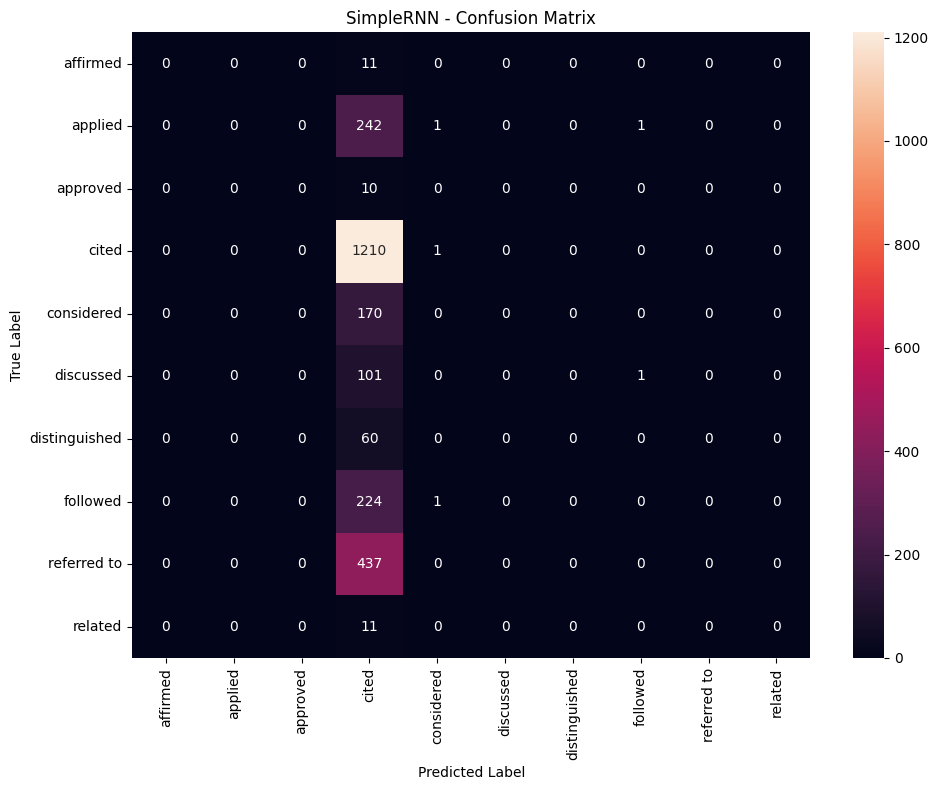

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_rnn = confusion_matrix(
    y_test_encoded,
    y_test_pred_rnn
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_rnn,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("SimpleRNN - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

BIDIRECTIONAL SIMPLERNN

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout, Bidirectional

birnn_1 = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=True
    ),

    Bidirectional(
        SimpleRNN(64)
    ),

    Dropout(0.4),

    Dense(
        64,
        activation="relu"
    ),

    Dropout(0.3),

    Dense(
        num_classes,
        activation="softmax"
    )
])

birnn_1.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0005
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping_birnn_1 = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_birnn_1 = birnn_1.fit(
    X_train_seq,
    y_train_encoded,
    validation_data=(X_val_seq, y_val_encoded),
    epochs=15,
    batch_size=32,
    callbacks=[early_stopping_birnn_2]
)

Epoch 1/15
621/621 ━━━━━━━━━━━━━━━━━━━━ 73s 110ms/step - accuracy: 0.4644 - loss: 1.6794 - val_accuracy: 0.4881 - val_loss: 1.5648
Epoch 2/15
621/621 ━━━━━━━━━━━━━━━━━━━━ 55s 88ms/step - accuracy: 0.4847 - loss: 1.6002 - val_accuracy: 0.4881 - val_loss: 1.5642
Epoch 3/15
621/621 ━━━━━━━━━━━━━━━━━━━━ 55s 88ms/step - accuracy: 0.4873 - loss: 1.5648 - val_accuracy: 0.4881 - val_loss: 1.5880
Epoch 4/15
621/621 ━━━━━━━━━━━━━━━━━━━━ 55s 89ms/step - accuracy: 0.4895 - loss: 1.5050 - val_accuracy: 0.4829 - val_loss: 1.5989
Epoch 5/15
621/621 ━━━━━━━━━━━━━━━━━━━━ 55s 88ms/step - accuracy: 0.4965 - loss: 1.4327 - val_accuracy: 0.4692 - val_loss: 1.6575
Epoch 6/15
621/621 ━━━━━━━━━━━━━━━━━━━━ 55s 88ms/step - accuracy: 0.5157 - loss: 1.3558 - val_accuracy: 0.4426 - val_loss: 1.7097


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf

birnn_2 = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=True
    ),

    Bidirectional(
        SimpleRNN(128)
    ),

    Dropout(0.5),

    Dense(128, activation="relu"),
    Dropout(0.4),

    Dense(64, activation="relu"),
    Dropout(0.3),

    Dense(32, activation="relu"),
    Dropout(0.2),

    Dense(num_classes, activation="softmax")
])

birnn_2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping_birnn_2 = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

history_birnn_2 = birnn_1.fit(
    X_train_seq,
    y_train_encoded,
    validation_data=(X_val_seq, y_val_encoded),
    epochs=20,
    batch_size=32,
    callbacks=[early_stopping_birnn_1]
)

Epoch 1/20
621/621 ━━━━━━━━━━━━━━━━━━━━ 56s 90ms/step - accuracy: 0.4876 - loss: 1.5793 - val_accuracy: 0.4881 - val_loss: 1.5550
Epoch 2/20
621/621 ━━━━━━━━━━━━━━━━━━━━ 81s 89ms/step - accuracy: 0.4868 - loss: 1.5479 - val_accuracy: 0.4881 - val_loss: 1.5672
Epoch 3/20
621/621 ━━━━━━━━━━━━━━━━━━━━ 55s 88ms/step - accuracy: 0.4916 - loss: 1.4767 - val_accuracy: 0.4857 - val_loss: 1.5918
Epoch 4/20
621/621 ━━━━━━━━━━━━━━━━━━━━ 55s 88ms/step - accuracy: 0.5044 - loss: 1.3885 - val_accuracy: 0.4627 - val_loss: 1.6431


In [ ]:
birnn_3 = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=True
    ),

    Bidirectional(
        SimpleRNN(256)
    ),

    Dropout(0.5),

    Dense(
        128,
        activation="relu"
    ),

    Dropout(0.4),

    Dense(
        64,
        activation="relu"
    ),

    Dropout(0.3),

    Dense(
        num_classes,
        activation="softmax"
    )
])

birnn_3.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0006
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping_birnn_3 = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

history_birnn_3 = birnn_3.fit(
    X_train_seq,
    y_train_encoded,
    validation_data=(X_val_seq, y_val_encoded),
    epochs=20,
    batch_size=32,
    callbacks=[early_stopping_birnn_3]
)

Epoch 1/20
621/621 ━━━━━━━━━━━━━━━━━━━━ 74s 110ms/step - accuracy: 0.4724 - loss: 1.6979 - val_accuracy: 0.4881 - val_loss: 1.6915
Epoch 2/20
621/621 ━━━━━━━━━━━━━━━━━━━━ 64s 104ms/step - accuracy: 0.4867 - loss: 1.6292 - val_accuracy: 0.4881 - val_loss: 1.6011
Epoch 3/20
621/621 ━━━━━━━━━━━━━━━━━━━━ 64s 103ms/step - accuracy: 0.4866 - loss: 1.6183 - val_accuracy: 0.4881 - val_loss: 1.6032
Epoch 4/20
621/621 ━━━━━━━━━━━━━━━━━━━━ 64s 103ms/step - accuracy: 0.4881 - loss: 1.6022 - val_accuracy: 0.4881 - val_loss: 1.6284
Epoch 5/20
621/621 ━━━━━━━━━━━━━━━━━━━━ 64s 104ms/step - accuracy: 0.4881 - loss: 1.5924 - val_accuracy: 0.4881 - val_loss: 1.5852
Epoch 6/20
621/621 ━━━━━━━━━━━━━━━━━━━━ 64s 104ms/step - accuracy: 0.4879 - loss: 1.5867 - val_accuracy: 0.4881 - val_loss: 1.5814
Epoch 7/20
621/621 ━━━━━━━━━━━━━━━━━━━━ 64s 103ms/step - accuracy: 0.4877 - loss: 1.5831 - val_accuracy: 0.4881 - val_loss: 1.5643
Epoch 8/20
621/621 ━━━━━━━━━━━━━━━━━━━━ 64s 103ms/step - accuracy: 0.4882 - loss: 1

In [ ]:
y_val_pred_birnn1 = np.argmax(
    birnn_1.predict(X_val_seq),
    axis=1
)

y_val_pred_birnn2 = np.argmax(
    birnn_2.predict(X_val_seq),
    axis=1
)

y_val_pred_birnn3 = np.argmax(
    birnn_3.predict(X_val_seq),
    axis=1
)

78/78 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step
78/78 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step
78/78 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step


In [ ]:
from sklearn.metrics import accuracy_score, f1_score

birnn1_accuracy = accuracy_score(y_val_encoded, y_val_pred_birnn1)
birnn1_f1 = f1_score(y_val_encoded, y_val_pred_birnn1, average="macro")

birnn2_accuracy = accuracy_score(y_val_encoded, y_val_pred_birnn2)
birnn2_f1 = f1_score(y_val_encoded, y_val_pred_birnn2, average="macro")

birnn3_accuracy = accuracy_score(y_val_encoded, y_val_pred_birnn3)
birnn3_f1 = f1_score(y_val_encoded, y_val_pred_birnn3, average="macro")

print("Bi-SimpleRNN 1 - Accuracy:", birnn1_accuracy, "Macro F1:", birnn1_f1)
print("Bi-SimpleRNN 2 - Accuracy:", birnn2_accuracy, "Macro F1:", birnn2_f1)
print("Bi-SimpleRNN 3 - Accuracy:", birnn3_accuracy, "Macro F1:", birnn3_f1)

Bi-SimpleRNN 1 - Accuracy: 0.48810963321241435 Macro F1: 0.06560130010834236
Bi-SimpleRNN 2 - Accuracy: 0.031035872632003223 Macro F1: 0.02487659342468261
Bi-SimpleRNN 3 - Accuracy: 0.48810963321241435 Macro F1: 0.06560130010834236


In [ ]:
birnn_tuning_results = pd.DataFrame({
    "Configuration": [
        "64 units, dropout=0.2",
        "128 units, dropout=0.3",
        "128 units, dropout=0.5"
    ],
    "Validation Accuracy": [
        birnn1_accuracy,
        birnn2_accuracy,
        birnn3_accuracy
    ],
    "Validation Macro F1": [
        birnn1_f1,
        birnn2_f1,
        birnn3_f1
    ]
})

birnn_tuning_results

,Configuration,Validation Accuracy,Validation Macro F1
0,"64 units, dropout=0.2",0.488110,0.065601
1,"128 units, dropout=0.3",0.031036,0.024877
2,"128 units, dropout=0.5",0.488110,0.065601


In [ ]:
best_birnn = birnn_1

In [ ]:
y_test_pred_birnn = np.argmax(
    best_birnn.predict(X_test_seq),
    axis=1
)

78/78 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step


In [ ]:
birnn_test_accuracy = accuracy_score(
    y_test_encoded,
    y_test_pred_birnn
)

birnn_test_f1 = f1_score(
    y_test_encoded,
    y_test_pred_birnn,
    average="macro"
)

print("Bidirectional SimpleRNN Test Accuracy:", birnn_test_accuracy)
print("Bidirectional SimpleRNN Test Macro F1:", birnn_test_f1)

Bidirectional SimpleRNN Test Accuracy: 0.48810963321241435
Bidirectional SimpleRNN Test Macro F1: 0.06560130010834236


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test_encoded,
    y_test_pred_birnn,
    target_names=label_encoder.classes_
))

               precision    recall  f1-score   support

     affirmed       0.00      0.00      0.00        11
      applied       0.00      0.00      0.00       244
     approved       0.00      0.00      0.00        10
        cited       0.49      1.00      0.66      1211
   considered       0.00      0.00      0.00       170
    discussed       0.00      0.00      0.00       102
distinguished       0.00      0.00      0.00        60
     followed       0.00      0.00      0.00       225
  referred to       0.00      0.00      0.00       437
      related       0.00      0.00      0.00        11

     accuracy                           0.49      2481
    macro avg       0.05      0.10      0.07      2481
 weighted avg       0.24      0.49      0.32      2481



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


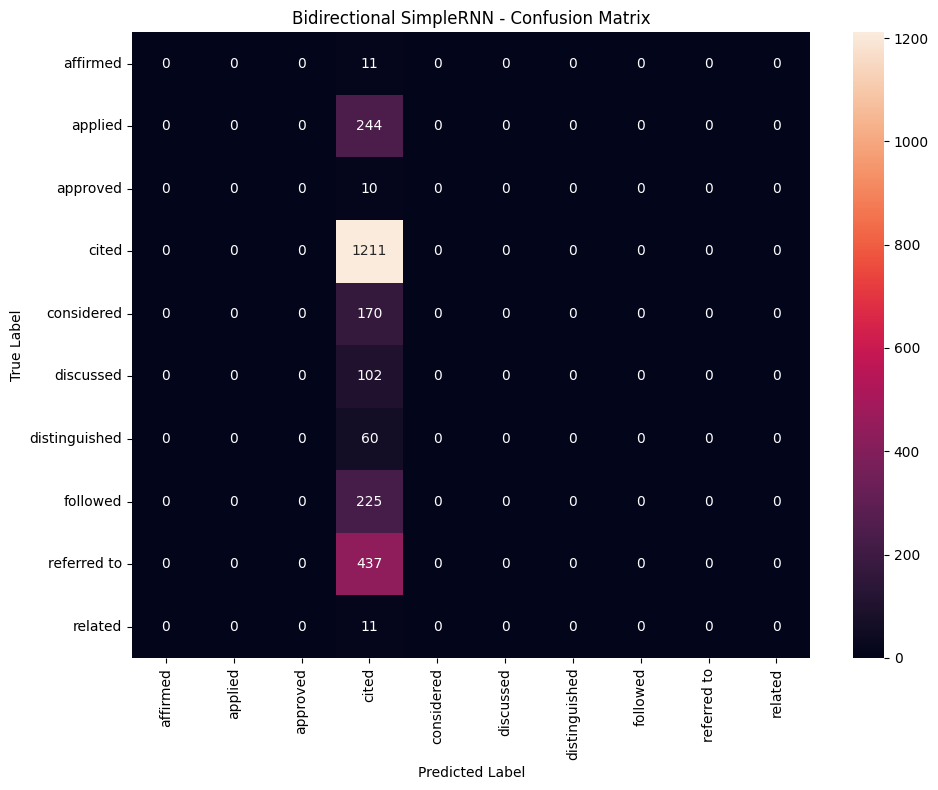

In [ ]:
cm_birnn = confusion_matrix(
    y_test_encoded,
    y_test_pred_birnn
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_birnn,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Bidirectional SimpleRNN - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

GRU

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train_encoded),
    y=y_train_encoded
)

class_weight_dict = dict(
    zip(np.unique(y_train_encoded), class_weights)
)

print(class_weight_dict)

{np.int64(0): np.float64(23.34941176470588), np.int64(1): np.float64(1.0177948717948717), np.int64(2): np.float64(22.81264367816092), np.int64(3): np.float64(0.20486168455821635), np.int64(4): np.float64(1.460412067696836), np.int64(5): np.float64(2.438206388206388), np.int64(6): np.float64(4.117634854771784), np.int64(7): np.float64(1.101387347391787), np.int64(8): np.float64(0.5686819484240687), np.int64(9): np.float64(22.052222222222223)}


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GRU, Dense, Dropout

gru_1 = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=True
    ),

    GRU(64),
    Dropout(0.3),

    Dense(num_classes, activation="softmax")
])

gru_1.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_gru_1 = gru_1.fit(
    X_train_seq,
    y_train_encoded,
    validation_data=(X_val_seq, y_val_encoded),
    epochs=10,
    batch_size=64,
    callbacks=[early_stopping],

)

Epoch 1/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 15s 33ms/step - accuracy: 0.4821 - loss: 1.6119 - val_accuracy: 0.4881 - val_loss: 1.5646
Epoch 2/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.4896 - loss: 1.5651 - val_accuracy: 0.4857 - val_loss: 1.5616
Epoch 3/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.5005 - loss: 1.5341 - val_accuracy: 0.4825 - val_loss: 1.5717
Epoch 4/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 10s 32ms/step - accuracy: 0.5250 - loss: 1.4896 - val_accuracy: 0.4829 - val_loss: 1.5906


In [ ]:
gru_2 = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=True
    ),

    GRU(128),
    Dropout(0.3),

    Dense(64, activation="relu"),
    Dropout(0.3),

    Dense(num_classes, activation="softmax")
])

gru_2.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_gru_2 = gru_2.fit(
    X_train_seq,
    y_train_encoded,
    validation_data=(X_val_seq, y_val_encoded),
    epochs=10,
    batch_size=64,
    callbacks=[early_stopping_birnn_3],
)

Epoch 1/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 19s 40ms/step - accuracy: 0.4805 - loss: 1.6494 - val_accuracy: 0.4881 - val_loss: 1.5710
Epoch 2/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 11s 37ms/step - accuracy: 0.4888 - loss: 1.5816 - val_accuracy: 0.4873 - val_loss: 1.5623
Epoch 3/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - accuracy: 0.4937 - loss: 1.5568 - val_accuracy: 0.4829 - val_loss: 1.5740
Epoch 4/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - accuracy: 0.5103 - loss: 1.5162 - val_accuracy: 0.4792 - val_loss: 1.5985
Epoch 5/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - accuracy: 0.5336 - loss: 1.4595 - val_accuracy: 0.4796 - val_loss: 1.6656
Epoch 6/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - accuracy: 0.5561 - loss: 1.3991 - val_accuracy: 0.4776 - val_loss: 1.7353


In [ ]:
gru_3 = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=True
    ),

    GRU(256),
    Dropout(0.5),

    Dense(64, activation="relu"),
    Dropout(0.2),

    Dense(num_classes, activation="softmax")
])

gru_3.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_gru_3 = gru_3.fit(
    X_train_seq,
    y_train_encoded,
    validation_data=(X_val_seq, y_val_encoded),
    epochs=5,
    batch_size=64,
    callbacks=[early_stopping_birnn_3],
)

Epoch 1/5
311/311 ━━━━━━━━━━━━━━━━━━━━ 19s 54ms/step - accuracy: 0.4805 - loss: 1.6324 - val_accuracy: 0.4881 - val_loss: 1.5628
Epoch 2/5
311/311 ━━━━━━━━━━━━━━━━━━━━ 17s 55ms/step - accuracy: 0.4884 - loss: 1.5779 - val_accuracy: 0.4841 - val_loss: 1.5686
Epoch 3/5
311/311 ━━━━━━━━━━━━━━━━━━━━ 18s 58ms/step - accuracy: 0.4927 - loss: 1.5554 - val_accuracy: 0.4857 - val_loss: 1.5752
Epoch 4/5
311/311 ━━━━━━━━━━━━━━━━━━━━ 19s 61ms/step - accuracy: 0.5072 - loss: 1.5177 - val_accuracy: 0.4772 - val_loss: 1.6241


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

y_val_pred_gru1 = np.argmax(
    gru_1.predict(X_val_seq),
    axis=1
)

y_val_pred_gru2 = np.argmax(
    gru_2.predict(X_val_seq),
    axis=1
)

y_val_pred_gru3 = np.argmax(
    gru_3.predict(X_val_seq),
    axis=1
)

78/78 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step
78/78 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step


In [ ]:
gru1_accuracy = accuracy_score(y_val_encoded, y_val_pred_gru1)
gru1_f1 = f1_score(y_val_encoded, y_val_pred_gru1, average="macro")

gru2_accuracy = accuracy_score(y_val_encoded, y_val_pred_gru2)
gru2_f1 = f1_score(y_val_encoded, y_val_pred_gru2, average="macro")

gru3_accuracy = accuracy_score(y_val_encoded, y_val_pred_gru3)
gru3_f1 = f1_score(y_val_encoded, y_val_pred_gru3, average="macro")

print("GRU 1 - Accuracy:", gru1_accuracy, "Macro F1:", gru1_f1)
print("GRU 2 - Accuracy:", gru2_accuracy, "Macro F1:", gru2_f1)
print("GRU 3 - Accuracy:", gru3_accuracy, "Macro F1:", gru3_f1)

GRU 1 - Accuracy: 0.4856912535268037 Macro F1: 0.06641221374045801
GRU 2 - Accuracy: 0.4873035066505441 Macro F1: 0.07202173438942058
GRU 3 - Accuracy: 0.48810963321241435 Macro F1: 0.06560130010834236


In [ ]:
gru_tuning_results = pd.DataFrame({
    "Configuration": [
        "64 units, dropout=0.2",
        "128 units, dropout=0.3",
        "128 units, dropout=0.5"
    ],
    "Validation Accuracy": [
        gru1_accuracy,
        gru2_accuracy,
        gru3_accuracy
    ],
    "Validation Macro F1": [
        gru1_f1,
        gru2_f1,
        gru3_f1
    ]
})

gru_tuning_results

,Configuration,Validation Accuracy,Validation Macro F1
0,"64 units, dropout=0.2",0.485691,0.066412
1,"128 units, dropout=0.3",0.487304,0.072022
2,"128 units, dropout=0.5",0.488110,0.065601


In [ ]:
best_gru = gru_2

In [ ]:
y_test_pred_gru = np.argmax(
    best_gru.predict(X_test_seq),
    axis=1
)

78/78 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step


In [ ]:
gru_test_accuracy = accuracy_score(
    y_test_encoded,
    y_test_pred_gru
)

gru_test_f1 = f1_score(
    y_test_encoded,
    y_test_pred_gru,
    average="macro"
)

print("GRU Test Accuracy:", gru_test_accuracy)
print("GRU Test Macro F1:", gru_test_f1)

GRU Test Accuracy: 0.4852881902458686
GRU Test Macro F1: 0.07000838935459522


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test_encoded,
    y_test_pred_gru,
    target_names=label_encoder.classes_
))

               precision    recall  f1-score   support

     affirmed       0.00      0.00      0.00        11
      applied       0.14      0.01      0.02       244
     approved       0.00      0.00      0.00        10
        cited       0.49      0.99      0.66      1211
   considered       0.17      0.01      0.02       170
    discussed       0.00      0.00      0.00       102
distinguished       0.00      0.00      0.00        60
     followed       0.00      0.00      0.00       225
  referred to       0.00      0.00      0.00       437
      related       0.00      0.00      0.00        11

     accuracy                           0.49      2481
    macro avg       0.08      0.10      0.07      2481
 weighted avg       0.26      0.49      0.32      2481



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


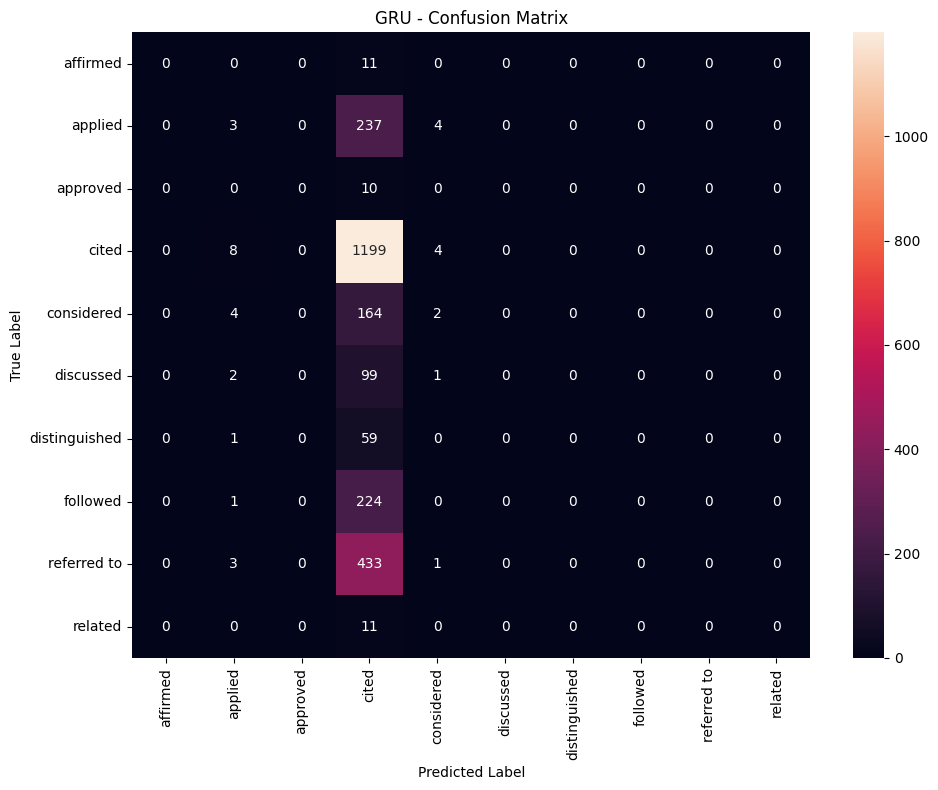

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_gru = confusion_matrix(
    y_test_encoded,
    y_test_pred_gru
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_gru,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("GRU - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

BIDIRECTIONAL GRU

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GRU, Dense, Dropout, Bidirectional

bigru_1 = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=False
    ),

    Bidirectional(GRU(64)),
    Dropout(0.2),

    Dense(num_classes, activation="softmax")
])

bigru_1.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

bigru_1.fit(
    X_train_seq,
    y_train_encoded,
    validation_data=(X_val_seq, y_val_encoded),
    epochs=10,
    batch_size=64,
    callbacks=[early_stopping],

)

Epoch 1/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 17s 46ms/step - accuracy: 0.4839 - loss: 1.5976 - val_accuracy: 0.4881 - val_loss: 1.5626
Epoch 2/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 14s 45ms/step - accuracy: 0.4883 - loss: 1.5526 - val_accuracy: 0.4877 - val_loss: 1.5392
Epoch 3/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 14s 45ms/step - accuracy: 0.4918 - loss: 1.5187 - val_accuracy: 0.4893 - val_loss: 1.5281
Epoch 4/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 27s 65ms/step - accuracy: 0.4935 - loss: 1.4944 - val_accuracy: 0.4869 - val_loss: 1.5215
Epoch 5/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 19s 59ms/step - accuracy: 0.4989 - loss: 1.4666 - val_accuracy: 0.4857 - val_loss: 1.5083
Epoch 6/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 14s 45ms/step - accuracy: 0.5070 - loss: 1.4368 - val_accuracy: 0.4841 - val_loss: 1.5032
Epoch 7/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 14s 45ms/step - accuracy: 0.5097 - loss: 1.4086 - val_accuracy: 0.4825 - val_loss: 1.5126
Epoch 8/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 20s 66ms/step - accuracy: 0.5186 - loss: 1.3784 - 

In [ ]:
bigru_2 = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=False
    ),

    Bidirectional(GRU(128)),
    Dropout(0.6),

    Dense(64, activation="relu"),
    Dropout(0.5),

    Dense(32, activation="relu"),
    Dropout(0.5),

    Dense(num_classes, activation="softmax")
])

bigru_2.compile(
    optimizer=tf.keras.optimizers.RMSprop(
        learning_rate=0.0005
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

bigru_2.fit(
    X_train_seq,
    y_train_encoded,
    validation_data=(X_val_seq, y_val_encoded),
    epochs=15,
    batch_size=64,
    callbacks=[early_stopping_birnn_3]
)

Epoch 1/15
311/311 ━━━━━━━━━━━━━━━━━━━━ 22s 58ms/step - accuracy: 0.4259 - loss: 1.8219 - val_accuracy: 0.4881 - val_loss: 1.6223
Epoch 2/15
311/311 ━━━━━━━━━━━━━━━━━━━━ 18s 57ms/step - accuracy: 0.4824 - loss: 1.6655 - val_accuracy: 0.4881 - val_loss: 1.5667
Epoch 3/15
311/311 ━━━━━━━━━━━━━━━━━━━━ 18s 58ms/step - accuracy: 0.4872 - loss: 1.6346 - val_accuracy: 0.4881 - val_loss: 1.5849
Epoch 4/15
311/311 ━━━━━━━━━━━━━━━━━━━━ 18s 57ms/step - accuracy: 0.4881 - loss: 1.6113 - val_accuracy: 0.4881 - val_loss: 1.5776


In [ ]:
bigru_3 = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=False
    ),

    Bidirectional(GRU(256)),
    Dropout(0.5),

    Dense(num_classes, activation="softmax")
])

bigru_3.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

bigru_3.fit(
    X_train_seq,
    y_train_encoded,
    validation_data=(X_val_seq, y_val_encoded),
    epochs=15,
    batch_size=64,
    callbacks=[early_stopping_birnn_3],

)

Epoch 1/15
311/311 ━━━━━━━━━━━━━━━━━━━━ 38s 109ms/step - accuracy: 0.4800 - loss: 1.5940 - val_accuracy: 0.4881 - val_loss: 1.5519
Epoch 2/15
311/311 ━━━━━━━━━━━━━━━━━━━━ 31s 100ms/step - accuracy: 0.4871 - loss: 1.5416 - val_accuracy: 0.4877 - val_loss: 1.5434
Epoch 3/15
311/311 ━━━━━━━━━━━━━━━━━━━━ 31s 101ms/step - accuracy: 0.4918 - loss: 1.5108 - val_accuracy: 0.4881 - val_loss: 1.5158
Epoch 4/15
311/311 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - accuracy: 0.4952 - loss: 1.4765 - val_accuracy: 0.4881 - val_loss: 1.5061
Epoch 5/15
311/311 ━━━━━━━━━━━━━━━━━━━━ 40s 104ms/step - accuracy: 0.5041 - loss: 1.4426 - val_accuracy: 0.4905 - val_loss: 1.4907
Epoch 6/15
311/311 ━━━━━━━━━━━━━━━━━━━━ 32s 104ms/step - accuracy: 0.5103 - loss: 1.4043 - val_accuracy: 0.4861 - val_loss: 1.4900
Epoch 7/15
311/311 ━━━━━━━━━━━━━━━━━━━━ 32s 104ms/step - accuracy: 0.5224 - loss: 1.3485 - val_accuracy: 0.4821 - val_loss: 1.5292
Epoch 8/15
311/311 ━━━━━━━━━━━━━━━━━━━━ 33s 105ms/step - accuracy: 0.5454 - loss: 1

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

y_val_pred_bigru1 = np.argmax(
    bigru_1.predict(X_val_seq),
    axis=1
)

y_val_pred_bigru2 = np.argmax(
    bigru_2.predict(X_val_seq),
    axis=1
)

y_val_pred_bigru3 = np.argmax(
    bigru_3.predict(X_val_seq),
    axis=1
)

bigru1_accuracy = accuracy_score(y_val_encoded, y_val_pred_bigru1)
bigru1_f1 = f1_score(
    y_val_encoded,
    y_val_pred_bigru1,
    average="macro"
)

bigru2_accuracy = accuracy_score(y_val_encoded, y_val_pred_bigru2)
bigru2_f1 = f1_score(
    y_val_encoded,
    y_val_pred_bigru2,
    average="macro"
)

bigru3_accuracy = accuracy_score(y_val_encoded, y_val_pred_bigru3)
bigru3_f1 = f1_score(
    y_val_encoded,
    y_val_pred_bigru3,
    average="macro"
)

print("BiGRU 1 - Accuracy:", bigru1_accuracy, "Macro F1:", bigru1_f1)
print("BiGRU 2 - Accuracy:", bigru2_accuracy, "Macro F1:", bigru2_f1)
print("BiGRU 3 - Accuracy:", bigru3_accuracy, "Macro F1:", bigru3_f1)

78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step
78/78 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step
78/78 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step
BiGRU 1 - Accuracy: 0.4840790004030633 Macro F1: 0.08656862372226362
BiGRU 2 - Accuracy: 0.48810963321241435 Macro F1: 0.06560130010834236
BiGRU 3 - Accuracy: 0.4860943168077388 Macro F1: 0.14942489278350155


In [ ]:
bigru_tuning_results = pd.DataFrame({
    "Configuration": [
        "64 units, dropout=0.2",
        "128 units, dropout=0.3",
        "128 units, dropout=0.5"
    ],
    "Validation Accuracy": [
        bigru1_accuracy,
        bigru2_accuracy,
        bigru3_accuracy
    ],
    "Validation Macro F1": [
        bigru1_f1,
        bigru2_f1,
        bigru3_f1
    ]
})

bigru_tuning_results

,Configuration,Validation Accuracy,Validation Macro F1
0,"64 units, dropout=0.2",0.484079,0.086569
1,"128 units, dropout=0.3",0.488110,0.065601
2,"128 units, dropout=0.5",0.486094,0.149425


In [ ]:
best_bigru = bigru_3

In [ ]:
y_test_pred_bigru = np.argmax(
    best_bigru.predict(X_test_seq),
    axis=1
)

78/78 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step


In [ ]:
bigru_test_accuracy = accuracy_score(
    y_test_encoded,
    y_test_pred_bigru
)

bigru_test_f1 = f1_score(
    y_test_encoded,
    y_test_pred_bigru,
    average="macro"
)

print("Bidirectional GRU Test Accuracy:", bigru_test_accuracy)
print("Bidirectional GRU Test Macro F1:", bigru_test_f1)

Bidirectional GRU Test Accuracy: 0.4840790004030633
Bidirectional GRU Test Macro F1: 0.14283605271247787


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test_encoded,
    y_test_pred_bigru,
    target_names=label_encoder.classes_
))

               precision    recall  f1-score   support

     affirmed       0.29      0.36      0.32        11
      applied       0.22      0.07      0.10       244
     approved       0.00      0.00      0.00        10
        cited       0.51      0.96      0.67      1211
   considered       0.16      0.04      0.06       170
    discussed       0.09      0.01      0.02       102
distinguished       0.33      0.03      0.06        60
     followed       0.13      0.02      0.04       225
  referred to       0.29      0.02      0.03       437
      related       0.25      0.09      0.13        11

     accuracy                           0.48      2481
    macro avg       0.23      0.16      0.14      2481
 weighted avg       0.36      0.48      0.35      2481



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


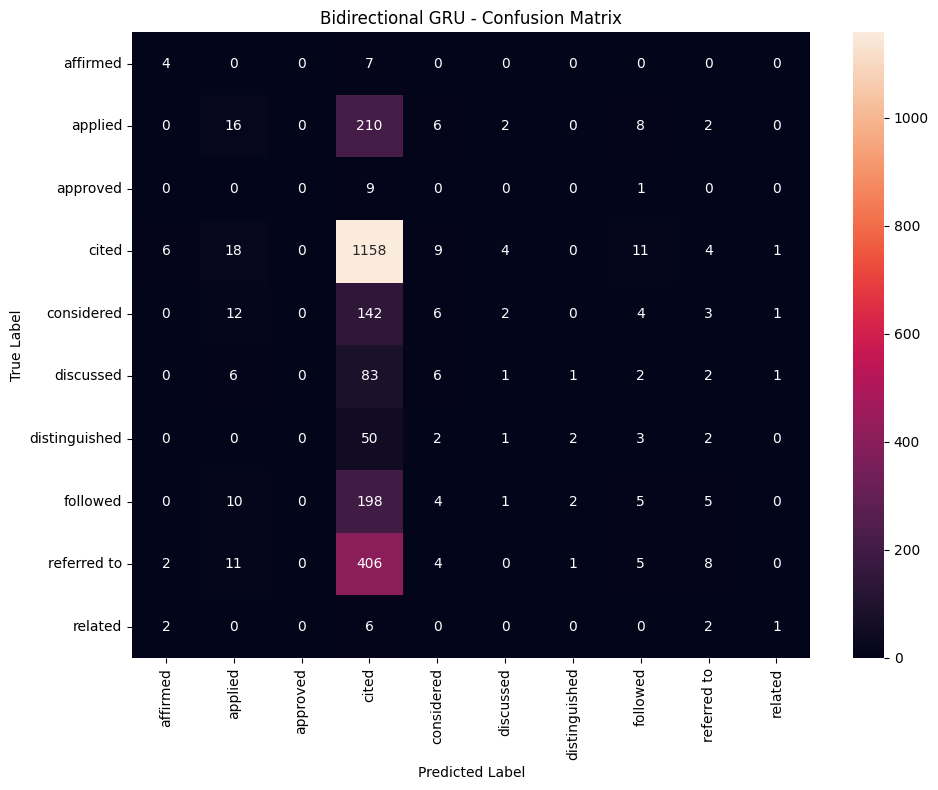

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_bigru = confusion_matrix(
    y_test_encoded,
    y_test_pred_bigru
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_bigru,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Bidirectional GRU - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

**LSTM**

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

lstm_1 = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=False
    ),

    LSTM(64),
    Dropout(0.2),

    Dense(num_classes, activation="softmax")
])

lstm_1.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

lstm_1.fit(
    X_train_seq,
    y_train_encoded,
    validation_data=(X_val_seq, y_val_encoded),
    epochs=10,
    batch_size=64,
    callbacks=[early_stopping]
)

Epoch 1/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.4851 - loss: 1.6335 - val_accuracy: 0.4881 - val_loss: 1.5639
Epoch 2/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.4880 - loss: 1.5735 - val_accuracy: 0.4881 - val_loss: 1.5668
Epoch 3/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 14s 44ms/step - accuracy: 0.4883 - loss: 1.5638 - val_accuracy: 0.4881 - val_loss: 1.5682
Epoch 4/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - accuracy: 0.4889 - loss: 1.5606 - val_accuracy: 0.4845 - val_loss: 1.5618
Epoch 5/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.4905 - loss: 1.5535 - val_accuracy: 0.4881 - val_loss: 1.5637


In [ ]:
lstm_2 = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=False
    ),

    LSTM(128),
    Dropout(0.5),

    Dense(num_classes, activation="softmax")
])

lstm_2.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

lstm_2.fit(
    X_train_seq,
    y_train_encoded,
    validation_data=(X_val_seq, y_val_encoded),
    epochs=16,
    batch_size=64,
    callbacks=[early_stopping_birnn_3]
)

Epoch 1/16
311/311 ━━━━━━━━━━━━━━━━━━━━ 12s 34ms/step - accuracy: 0.4838 - loss: 1.6239 - val_accuracy: 0.4881 - val_loss: 1.5640
Epoch 2/16
311/311 ━━━━━━━━━━━━━━━━━━━━ 10s 33ms/step - accuracy: 0.4881 - loss: 1.5797 - val_accuracy: 0.4881 - val_loss: 1.5612
Epoch 3/16
311/311 ━━━━━━━━━━━━━━━━━━━━ 10s 33ms/step - accuracy: 0.4881 - loss: 1.5697 - val_accuracy: 0.4881 - val_loss: 1.5633
Epoch 4/16
311/311 ━━━━━━━━━━━━━━━━━━━━ 10s 34ms/step - accuracy: 0.4887 - loss: 1.5644 - val_accuracy: 0.4877 - val_loss: 1.5640


In [ ]:
lstm_3 = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=False
    ),

    LSTM(256),
    Dropout(0.5),

    Dense(128, activation="relu"),
    Dropout(0.4),

    Dense(num_classes, activation="softmax")
])

lstm_3.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

lstm_3.fit(
    X_train_seq,
    y_train_encoded,
    validation_data=(X_val_seq, y_val_encoded),
    epochs=10,
    batch_size=64,
    callbacks=[early_stopping_birnn_2]
)

Epoch 1/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 20s 60ms/step - accuracy: 0.4804 - loss: 1.6424 - val_accuracy: 0.4881 - val_loss: 1.5653
Epoch 2/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 22s 64ms/step - accuracy: 0.4881 - loss: 1.5876 - val_accuracy: 0.4881 - val_loss: 1.5802
Epoch 3/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 19s 62ms/step - accuracy: 0.4880 - loss: 1.5812 - val_accuracy: 0.4881 - val_loss: 1.5625
Epoch 4/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 19s 61ms/step - accuracy: 0.4877 - loss: 1.5753 - val_accuracy: 0.4881 - val_loss: 1.5618
Epoch 5/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 20s 64ms/step - accuracy: 0.4830 - loss: 1.6057 - val_accuracy: 0.4885 - val_loss: 1.5601
Epoch 6/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 20s 63ms/step - accuracy: 0.4880 - loss: 1.5685 - val_accuracy: 0.4881 - val_loss: 1.5655
Epoch 7/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 20s 63ms/step - accuracy: 0.4883 - loss: 1.5627 - val_accuracy: 0.4881 - val_loss: 1.5613
Epoch 8/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 20s 63ms/step - accuracy: 0.4896 - loss: 1.5583 - 

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

y_val_pred_lstm1 = np.argmax(
    lstm_1.predict(X_val_seq),
    axis=1
)

y_val_pred_lstm2 = np.argmax(
    lstm_2.predict(X_val_seq),
    axis=1
)

y_val_pred_lstm3 = np.argmax(
    lstm_3.predict(X_val_seq),
    axis=1
)

lstm1_accuracy = accuracy_score(y_val_encoded, y_val_pred_lstm1)
lstm1_f1 = f1_score(
    y_val_encoded,
    y_val_pred_lstm1,
    average="macro"
)

lstm2_accuracy = accuracy_score(y_val_encoded, y_val_pred_lstm2)
lstm2_f1 = f1_score(
    y_val_encoded,
    y_val_pred_lstm2,
    average="macro"
)

lstm3_accuracy = accuracy_score(y_val_encoded, y_val_pred_lstm3)
lstm3_f1 = f1_score(
    y_val_encoded,
    y_val_pred_lstm3,
    average="macro"
)

print("LSTM 1 - Accuracy:", lstm1_accuracy, "Macro F1:", lstm1_f1)
print("LSTM 2 - Accuracy:", lstm2_accuracy, "Macro F1:", lstm2_f1)
print("LSTM 3 - Accuracy:", lstm3_accuracy, "Macro F1:", lstm3_f1)

78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step
78/78 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step
78/78 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step
LSTM 1 - Accuracy: 0.48810963321241435 Macro F1: 0.06560130010834236
LSTM 2 - Accuracy: 0.48810963321241435 Macro F1: 0.06560130010834236
LSTM 3 - Accuracy: 0.48851269649334944 Macro F1: 0.06756082099465244


In [ ]:
lstm_tuning_results = pd.DataFrame({
    "Configuration": [
        "64 units, dropout=0.2",
        "128 units, dropout=0.3",
        "128 units, dropout=0.5"
    ],
    "Validation Accuracy": [
        lstm1_accuracy,
        lstm2_accuracy,
        lstm3_accuracy
    ],
    "Validation Macro F1": [
        lstm1_f1,
        lstm2_f1,
        lstm3_f1
    ]
})

lstm_tuning_results

,Configuration,Validation Accuracy,Validation Macro F1
0,"64 units, dropout=0.2",0.488110,0.065601
1,"128 units, dropout=0.3",0.488110,0.065601
2,"128 units, dropout=0.5",0.488513,0.067561


In [ ]:
best_lstm = lstm_2

In [ ]:
y_test_pred_lstm = np.argmax(
    best_lstm.predict(X_test_seq),
    axis=1
)

78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step


In [ ]:
lstm_test_accuracy = accuracy_score(
    y_test_encoded,
    y_test_pred_lstm
)

lstm_test_f1 = f1_score(
    y_test_encoded,
    y_test_pred_lstm,
    average="macro"
)

print("LSTM Test Accuracy:", lstm_test_accuracy)
print("LSTM Test Macro F1:", lstm_test_f1)

LSTM Test Accuracy: 0.48810963321241435
LSTM Test Macro F1: 0.06560130010834236


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test_encoded,
    y_test_pred_lstm,
    target_names=label_encoder.classes_
))

               precision    recall  f1-score   support

     affirmed       0.00      0.00      0.00        11
      applied       0.00      0.00      0.00       244
     approved       0.00      0.00      0.00        10
        cited       0.49      1.00      0.66      1211
   considered       0.00      0.00      0.00       170
    discussed       0.00      0.00      0.00       102
distinguished       0.00      0.00      0.00        60
     followed       0.00      0.00      0.00       225
  referred to       0.00      0.00      0.00       437
      related       0.00      0.00      0.00        11

     accuracy                           0.49      2481
    macro avg       0.05      0.10      0.07      2481
 weighted avg       0.24      0.49      0.32      2481



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


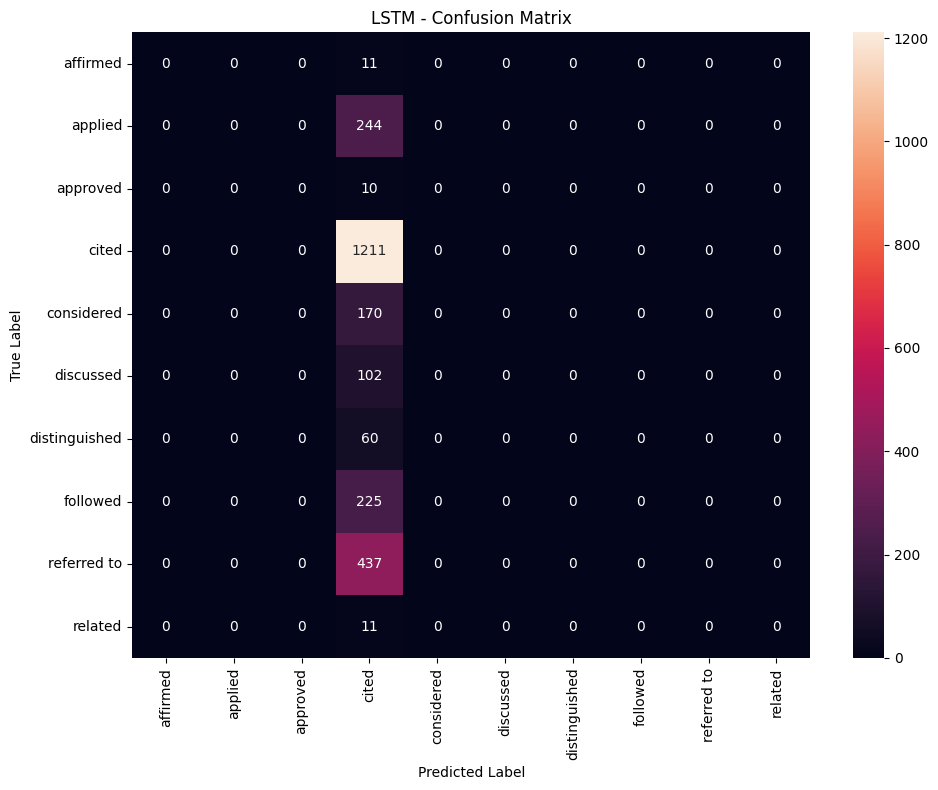

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_lstm = confusion_matrix(
    y_test_encoded,
    y_test_pred_lstm
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_lstm,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("LSTM - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

BIDIRECTIONAL LSTM

In [ ]:
bilstm_1 = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=False
    ),

    Bidirectional(LSTM(64)),
    Dropout(0.2),

    Dense(64, activation="relu"),
    Dropout(0.2),

    Dense(num_classes, activation="softmax")
])

bilstm_1.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

bilstm_1.fit(
    X_train_seq,
    y_train_encoded,
    validation_data=(X_val_seq, y_val_encoded),
    epochs=10,
    batch_size=64,
    callbacks=[early_stopping_birnn_3]
)

Epoch 1/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 25s 71ms/step - accuracy: 0.4852 - loss: 1.6117 - val_accuracy: 0.4881 - val_loss: 1.5612
Epoch 2/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 37s 57ms/step - accuracy: 0.4880 - loss: 1.5723 - val_accuracy: 0.4881 - val_loss: 1.5425
Epoch 3/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 19s 53ms/step - accuracy: 0.4880 - loss: 1.5427 - val_accuracy: 0.4881 - val_loss: 1.5140
Epoch 4/10
311/311 ━━━━━━━━━━━━━━━━━━━━ 15s 47ms/step - accuracy: 0.4879 - loss: 1.5192 - val_accuracy: 0.4885 - val_loss: 1.5027


In [ ]:
bilstm_2 = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=False
    ),

    Bidirectional(LSTM(128)),
    Dropout(0.5),

    Dense(num_classes, activation="softmax")
])

bilstm_2.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

bilstm_2.fit(
    X_train_seq,
    y_train_encoded,
    validation_data=(X_val_seq, y_val_encoded),
    epochs=12,
    batch_size=64,
    callbacks=[early_stopping]
)

Epoch 1/12
311/311 ━━━━━━━━━━━━━━━━━━━━ 23s 66ms/step - accuracy: 0.4831 - loss: 1.6016 - val_accuracy: 0.4881 - val_loss: 1.5586
Epoch 2/12
311/311 ━━━━━━━━━━━━━━━━━━━━ 22s 70ms/step - accuracy: 0.4869 - loss: 1.5507 - val_accuracy: 0.4901 - val_loss: 1.5157
Epoch 3/12
311/311 ━━━━━━━━━━━━━━━━━━━━ 40s 66ms/step - accuracy: 0.4880 - loss: 1.5189 - val_accuracy: 0.4889 - val_loss: 1.5194
Epoch 4/12
311/311 ━━━━━━━━━━━━━━━━━━━━ 20s 65ms/step - accuracy: 0.4915 - loss: 1.4984 - val_accuracy: 0.4905 - val_loss: 1.4976
Epoch 5/12
311/311 ━━━━━━━━━━━━━━━━━━━━ 20s 65ms/step - accuracy: 0.4935 - loss: 1.4765 - val_accuracy: 0.4853 - val_loss: 1.4867
Epoch 6/12
311/311 ━━━━━━━━━━━━━━━━━━━━ 22s 70ms/step - accuracy: 0.5002 - loss: 1.4487 - val_accuracy: 0.4946 - val_loss: 1.4810
Epoch 7/12
311/311 ━━━━━━━━━━━━━━━━━━━━ 20s 66ms/step - accuracy: 0.5050 - loss: 1.4257 - val_accuracy: 0.4925 - val_loss: 1.4754
Epoch 8/12
311/311 ━━━━━━━━━━━━━━━━━━━━ 20s 65ms/step - accuracy: 0.5141 - loss: 1.3933 - 

In [ ]:
bilstm_3 = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=False
    ),

    Bidirectional(LSTM(256)),
    Dropout(0.45),

    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(num_classes, activation="softmax")
])

bilstm_3.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

bilstm_3.fit(
    X_train_seq,
    y_train_encoded,
    validation_data=(X_val_seq, y_val_encoded),
    epochs=15,
    batch_size=64,
    callbacks=[early_stopping_birnn_3]
)

Epoch 1/15
311/311 ━━━━━━━━━━━━━━━━━━━━ 39s 119ms/step - accuracy: 0.4822 - loss: 1.6113 - val_accuracy: 0.4881 - val_loss: 1.5471
Epoch 2/15
311/311 ━━━━━━━━━━━━━━━━━━━━ 36s 117ms/step - accuracy: 0.4881 - loss: 1.5591 - val_accuracy: 0.4881 - val_loss: 1.5302
Epoch 3/15
311/311 ━━━━━━━━━━━━━━━━━━━━ 36s 117ms/step - accuracy: 0.4884 - loss: 1.5309 - val_accuracy: 0.4897 - val_loss: 1.5071
Epoch 4/15
311/311 ━━━━━━━━━━━━━━━━━━━━ 37s 118ms/step - accuracy: 0.4879 - loss: 1.5215 - val_accuracy: 0.4901 - val_loss: 1.5068


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

y_val_pred_bilstm1 = np.argmax(
    bilstm_1.predict(X_val_seq),
    axis=1
)

y_val_pred_bilstm2 = np.argmax(
    bilstm_2.predict(X_val_seq),
    axis=1
)

y_val_pred_bilstm3 = np.argmax(
    bilstm_3.predict(X_val_seq),
    axis=1
)

bilstm1_accuracy = accuracy_score(
    y_val_encoded,
    y_val_pred_bilstm1
)

bilstm1_f1 = f1_score(
    y_val_encoded,
    y_val_pred_bilstm1,
    average="macro"
)

bilstm2_accuracy = accuracy_score(
    y_val_encoded,
    y_val_pred_bilstm2
)

bilstm2_f1 = f1_score(
    y_val_encoded,
    y_val_pred_bilstm2,
    average="macro"
)

bilstm3_accuracy = accuracy_score(
    y_val_encoded,
    y_val_pred_bilstm3
)

bilstm3_f1 = f1_score(
    y_val_encoded,
    y_val_pred_bilstm3,
    average="macro"
)

print(
    "BiLSTM 1 - Accuracy:", bilstm1_accuracy,
    "Macro F1:", bilstm1_f1
)

print(
    "BiLSTM 2 - Accuracy:", bilstm2_accuracy,
    "Macro F1:", bilstm2_f1
)

print(
    "BiLSTM 3 - Accuracy:", bilstm3_accuracy,
    "Macro F1:", bilstm3_f1
)

78/78 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step
78/78 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step
78/78 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step
BiLSTM 1 - Accuracy: 0.48810963321241435 Macro F1: 0.06560130010834236
BiLSTM 2 - Accuracy: 0.49455864570737607 Macro F1: 0.18437225063885215
BiLSTM 3 - Accuracy: 0.48810963321241435 Macro F1: 0.06560130010834236


In [ ]:
bilstm_tuning_results = pd.DataFrame({
    "Configuration": [
        "64 units, dropout=0.2",
        "128 units, dropout=0.3",
        "128 units, dropout=0.5"
    ],
    "Validation Accuracy": [
        bilstm1_accuracy,
        bilstm2_accuracy,
        bilstm3_accuracy
    ],
    "Validation Macro F1": [
        bilstm1_f1,
        bilstm2_f1,
        bilstm3_f1
    ]
})

bilstm_tuning_results

,Configuration,Validation Accuracy,Validation Macro F1
0,"64 units, dropout=0.2",0.488110,0.065601
1,"128 units, dropout=0.3",0.494559,0.184372
2,"128 units, dropout=0.5",0.488110,0.065601


In [ ]:
best_bilstm = bilstm_2

In [ ]:
y_test_pred_bilstm = np.argmax(
    best_bilstm.predict(X_test_seq),
    axis=1
)

78/78 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step


In [ ]:
bilstm_test_accuracy = accuracy_score(
    y_test_encoded,
    y_test_pred_bilstm
)

bilstm_test_f1 = f1_score(
    y_test_encoded,
    y_test_pred_bilstm,
    average="macro"
)

print("Bidirectional LSTM Test Accuracy:", bilstm_test_accuracy)
print("Bidirectional LSTM Test Macro F1:", bilstm_test_f1)

Bidirectional LSTM Test Accuracy: 0.4873035066505441
Bidirectional LSTM Test Macro F1: 0.16053466375046518


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test_encoded,
    y_test_pred_bilstm,
    target_names=label_encoder.classes_
))

               precision    recall  f1-score   support

     affirmed       0.40      0.55      0.46        11
      applied       0.33      0.07      0.12       244
     approved       0.00      0.00      0.00        10
        cited       0.50      0.97      0.66      1211
   considered       0.19      0.05      0.08       170
    discussed       0.00      0.00      0.00       102
distinguished       0.14      0.02      0.03        60
     followed       0.07      0.00      0.01       225
  referred to       0.33      0.01      0.01       437
      related       0.21      0.27      0.24        11

     accuracy                           0.49      2481
    macro avg       0.22      0.19      0.16      2481
 weighted avg       0.36      0.49      0.35      2481



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


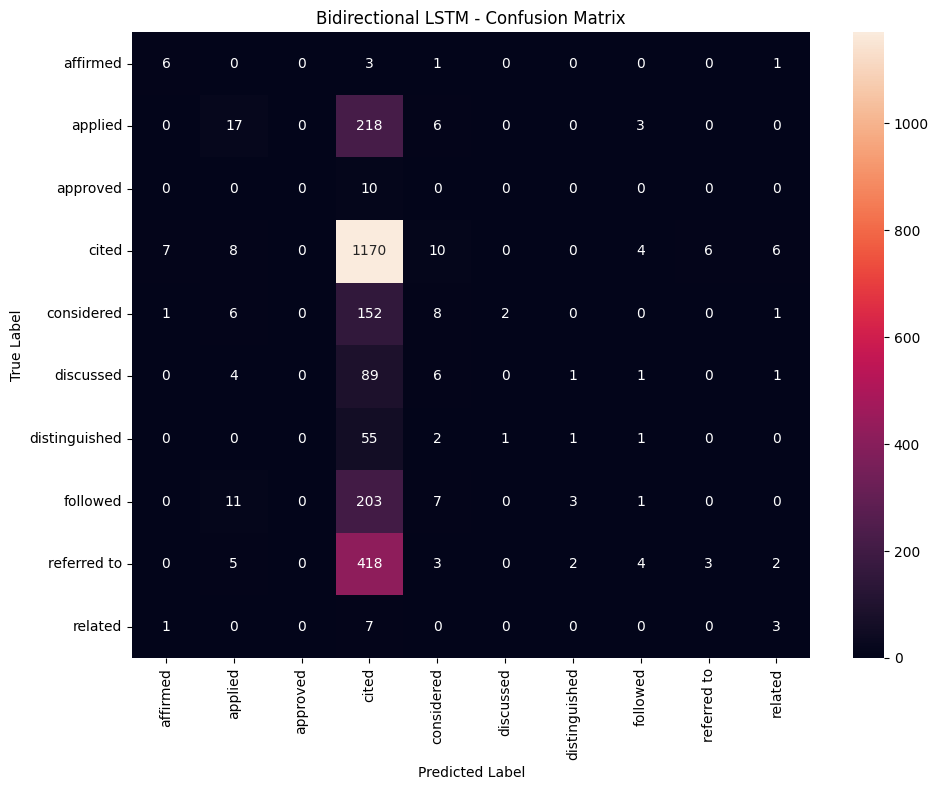

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_bilstm = confusion_matrix(
    y_test_encoded,
    y_test_pred_bilstm
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_bilstm,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Bidirectional LSTM - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

BERT BASE

In [ ]:
from sklearn.preprocessing import LabelEncoder
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.optim import AdamW
from transformers import get_scheduler
from tqdm.auto import tqdm
import numpy as np
from sklearn.metrics import accuracy_score, classification_report

le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_val_encoded = le.transform(y_val)
y_test_encoded = le.transform(y_test)

In [ ]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

class LegalTextDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=512):
        self.encodings = tokenizer(
            texts.tolist(),
            truncation=True,
            padding=True,
            max_length=max_length
        )
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)

train_dataset = LegalTextDataset(X_train, y_train_encoded, tokenizer)
val_dataset = LegalTextDataset(X_val, y_val_encoded, tokenizer)
test_dataset = LegalTextDataset(X_test, y_test_encoded, tokenizer)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_bert_2 = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=len(le.classes_)
)

model_bert_2.to(device)

train_loader_2 = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

val_loader_2 = DataLoader(
    val_dataset,
    batch_size=16
)

optimizer_2 = AdamW(
    model_bert_2.parameters(),
    lr=1e-5,
    weight_decay=0.01
)

num_epochs_2 = 3

num_training_steps_2 = (
    num_epochs_2 * len(train_loader_2)
)

lr_scheduler_2 = get_scheduler(
    name="linear",
    optimizer=optimizer_2,
    num_warmup_steps=0,
    num_training_steps=num_training_steps_2
)

best_val_f1_2 = -1
best_val_accuracy_2 = 0

for epoch in range(num_epochs_2):

    model_bert_2.train()
    total_train_loss_2 = 0

    progress_bar = tqdm(
        train_loader_2,
        desc=f"Epoch {epoch+1}/{num_epochs_2}"
    )

    for batch in progress_bar:

        batch = {
            k: v.to(device)
            for k, v in batch.items()
        }

        outputs = model_bert_2(**batch)

        loss = outputs.loss
        total_train_loss_2 += loss.item()

        loss.backward()

        optimizer_2.step()
        lr_scheduler_2.step()
        optimizer_2.zero_grad()

        progress_bar.set_postfix(
            loss=loss.item()
        )


    model_bert_2.eval()

    val_predictions_2 = []
    val_true_2 = []

    with torch.no_grad():

        for batch in val_loader_2:

            labels = batch["labels"].to(device)

            batch = {
                k: v.to(device)
                for k, v in batch.items()
            }

            outputs = model_bert_2(**batch)

            predictions = torch.argmax(
                outputs.logits,
                dim=-1
            )

            val_predictions_2.extend(
                predictions.cpu().numpy()
            )

            val_true_2.extend(
                labels.cpu().numpy()
            )

    val_accuracy_2 = accuracy_score(
        val_true_2,
        val_predictions_2
    )


    report_2 = classification_report(
        val_true_2,
        val_predictions_2,
        output_dict=True,
        zero_division=0
    )


    val_macro_f1_2 = report_2["macro avg"]["f1-score"]

    print(
        f"Epoch {epoch+1} | "
        f"Train Loss: {total_train_loss_2 / len(train_loader_2):.4f} | "
        f"Validation Accuracy: {val_accuracy_2:.4f} | "
        f"Validation Macro F1: {val_macro_f1_2:.4f}"
    )


    if val_macro_f1_2 > best_val_f1_2:

        best_val_f1_2 = val_macro_f1_2
        best_val_accuracy_2 = val_accuracy_2

        torch.save(
            model_bert_2.state_dict(),
            "best_bert_model_2.pt"
        )

        print("Best BERT 2 model saved.")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/3:   0%|          | 0/1241 [00:00<?, ?it/s]

Epoch 1 | Train Loss: 1.5583 | Validation Accuracy: 0.4877 | Validation Macro F1: 0.0656
Best BERT 2 model saved.


Epoch 2/3:   0%|          | 0/1241 [00:00<?, ?it/s]

Epoch 2 | Train Loss: 1.4327 | Validation Accuracy: 0.5038 | Validation Macro F1: 0.1118
Best BERT 2 model saved.


Epoch 3/3:   0%|          | 0/1241 [00:00<?, ?it/s]

Epoch 3 | Train Loss: 1.3276 | Validation Accuracy: 0.5107 | Validation Macro F1: 0.2100
Best BERT 2 model saved.


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_bert_1 = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=len(le.classes_)
)

model_bert_1.to(device)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8
)

optimizer = AdamW(
    model_bert_1.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

num_epochs = 2

num_training_steps = num_epochs * len(train_loader)

lr_scheduler = get_scheduler(
    name="linear",
    optimizer=optimizer,
    num_warmup_steps=0,
    num_training_steps=num_training_steps
)


best_val_f1 = -1
patience = 1
patience_counter = 0

for epoch in range(num_epochs):



    model_bert_1.train()
    total_train_loss = 0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{num_epochs}"
    )

    for batch in progress_bar:

        batch = {
            k: v.to(device)
            for k, v in batch.items()
        }

        outputs = model_bert_1(**batch)

        loss = outputs.loss
        total_train_loss += loss.item()

        loss.backward()

        optimizer.step()
        lr_scheduler.step()
        optimizer.zero_grad()

        progress_bar.set_postfix(
            loss=loss.item()
        )



    model_bert_1.eval()

    val_predictions = []
    val_true = []

    with torch.no_grad():

        for batch in val_loader:

            labels = batch["labels"].to(device)

            batch = {
                k: v.to(device)
                for k, v in batch.items()
            }

            outputs = model_bert_1(**batch)

            predictions = torch.argmax(
                outputs.logits,
                dim=-1
            )

            val_predictions.extend(
                predictions.cpu().numpy()
            )

            val_true.extend(
                labels.cpu().numpy()
            )


    val_accuracy = accuracy_score(
        val_true,
        val_predictions
    )


    report = classification_report(
        val_true,
        val_predictions,
        output_dict=True,
        zero_division=0
    )

    val_macro_f1 = report["macro avg"]["f1-score"]

    print(
        f"Epoch {epoch+1} | "
        f"Train Loss: {total_train_loss / len(train_loader):.4f} | "
        f"Validation Accuracy: {val_accuracy:.4f} | "
        f"Validation Macro F1: {val_macro_f1:.4f}"
    )



    if val_macro_f1 > best_val_f1:

        best_val_f1 = val_macro_f1
        patience_counter = 0

        torch.save(
            model_bert_1.state_dict(),
            "best_bert_model.pt"
        )

        print("Best model saved.")

    else:

        patience_counter += 1

        print(
            f"No improvement. "
            f"Patience: {patience_counter}/{patience}"
        )

        if patience_counter >= patience:

            print("Early stopping triggered.")
            break

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/2:   0%|          | 0/2481 [00:00<?, ?it/s]

Epoch 1 | Train Loss: 1.5153 | Validation Accuracy: 0.4933 | Validation Macro F1: 0.1337
Best model saved.


Epoch 2/2:   0%|          | 0/2481 [00:00<?, ?it/s]

Epoch 2 | Train Loss: 1.3541 | Validation Accuracy: 0.5075 | Validation Macro F1: 0.2632
Best model saved.


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_bert_3 = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=len(le.classes_)
)

model_bert_3.to(device)

train_loader_3 = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True
)

val_loader_3 = DataLoader(
    val_dataset,
    batch_size=8
)

optimizer_3 = AdamW(
    model_bert_3.parameters(),
    lr=3e-5,
    weight_decay=0.05
)

num_epochs_3 = 2

num_training_steps_3 = num_epochs_3 * len(train_loader_3)

num_warmup_steps_3 = int(
    0.1 * num_training_steps_3
)

lr_scheduler_3 = get_scheduler(
    name="linear",
    optimizer=optimizer_3,
    num_warmup_steps=num_warmup_steps_3,
    num_training_steps=num_training_steps_3
)


best_val_f1_3 = -1
patience_3 = 1
patience_counter_3 = 0

for epoch in range(num_epochs_3):



    model_bert_3.train()
    total_train_loss_3 = 0

    progress_bar = tqdm(
        train_loader_3,
        desc=f"Epoch {epoch+1}/{num_epochs_3}"
    )

    for batch in progress_bar:

        batch = {
            k: v.to(device)
            for k, v in batch.items()
        }

        outputs = model_bert_3(**batch)

        loss = outputs.loss
        total_train_loss_3 += loss.item()

        loss.backward()


        torch.nn.utils.clip_grad_norm_(
            model_bert_3.parameters(),
            max_norm=1.0
        )

        optimizer_3.step()
        lr_scheduler_3.step()
        optimizer_3.zero_grad()

        progress_bar.set_postfix(
            loss=loss.item()
        )



    model_bert_3.eval()

    val_predictions_3 = []
    val_true_3 = []

    with torch.no_grad():

        for batch in val_loader_3:

            labels = batch["labels"].to(device)

            batch = {
                k: v.to(device)
                for k, v in batch.items()
            }

            outputs = model_bert_3(**batch)

            predictions = torch.argmax(
                outputs.logits,
                dim=-1
            )

            val_predictions_3.extend(
                predictions.cpu().numpy()
            )

            val_true_3.extend(
                labels.cpu().numpy()
            )

    val_accuracy_3 = accuracy_score(
        val_true_3,
        val_predictions_3
    )

    report_3 = classification_report(
        val_true_3,
        val_predictions_3,
        output_dict=True,
        zero_division=0
    )

    val_macro_f1_3 = report_3["macro avg"]["f1-score"]

    print(
        f"Epoch {epoch+1} | "
        f"Train Loss: {total_train_loss_3 / len(train_loader_3):.4f} | "
        f"Validation Accuracy: {val_accuracy_3:.4f} | "
        f"Validation Macro F1: {val_macro_f1_3:.4f}"
    )



    if val_macro_f1_3 > best_val_f1_3:

        best_val_f1_3 = val_macro_f1_3
        patience_counter_3 = 0

        torch.save(
            model_bert_3.state_dict(),
            "best_bert_model_3.pt"
        )

        print("Best model saved.")

    else:

        patience_counter_3 += 1

        print(
            f"No improvement. "
            f"Patience: {patience_counter_3}/{patience_3}"
        )

        if patience_counter_3 >= patience_3:

            print("Early stopping triggered.")
            break

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/2:   0%|          | 0/2481 [00:00<?, ?it/s]

Epoch 1 | Train Loss: 1.5933 | Validation Accuracy: 0.4881 | Validation Macro F1: 0.0656
Best model saved.


Epoch 2/2:   0%|          | 0/2481 [00:00<?, ?it/s]

Epoch 2 | Train Loss: 1.4473 | Validation Accuracy: 0.4982 | Validation Macro F1: 0.1191
Best model saved.


TESTING AND REPORTS OF BERT 2

In [ ]:
test_loader_2 = DataLoader(
    test_dataset,
    batch_size=16
)

In [ ]:
model_bert_2.load_state_dict(
    torch.load(
        "best_bert_model_2.pt",
        map_location=device
    )
)

model_bert_2.to(device)
model_bert_2.eval()

print("Best BERT 2 model loaded.")

Best BERT 2 model loaded.


In [ ]:
test_predictions_2 = []
test_true_2 = []

with torch.no_grad():

    for batch in test_loader_2:

        labels = batch["labels"].to(device)

        batch = {
            k: v.to(device)
            for k, v in batch.items()
        }

        outputs = model_bert_2(**batch)

        predictions = torch.argmax(
            outputs.logits,
            dim=-1
        )

        test_predictions_2.extend(
            predictions.cpu().numpy()
        )

        test_true_2.extend(
            labels.cpu().numpy()
        )

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

test_accuracy_2 = accuracy_score(
    test_true_2,
    test_predictions_2
)

test_macro_f1_2 = f1_score(
    test_true_2,
    test_predictions_2,
    average="macro"
)

test_weighted_f1_2 = f1_score(
    test_true_2,
    test_predictions_2,
    average="weighted"
)

print(f"BERT 2 Test Accuracy: {test_accuracy_2:.4f}")
print(f"BERT 2 Test Macro F1: {test_macro_f1_2:.4f}")
print(f"BERT 2 Test Weighted F1: {test_weighted_f1_2:.4f}")

BERT 2 Test Accuracy: 0.5147
BERT 2 Test Macro F1: 0.2034
BERT 2 Test Weighted F1: 0.4485


In [ ]:
print("BERT 2 Test Classification Report:\n")

print(
    classification_report(
        test_true_2,
        test_predictions_2,
        target_names=le.classes_,
        zero_division=0
    )
)

BERT 2 Test Classification Report:

               precision    recall  f1-score   support

     affirmed       0.60      0.27      0.38        11
      applied       0.28      0.12      0.17       244
     approved       0.00      0.00      0.00        10
        cited       0.58      0.87      0.70      1211
   considered       0.14      0.02      0.04       170
    discussed       0.17      0.13      0.15       102
distinguished       0.19      0.05      0.08        60
     followed       0.49      0.10      0.16       225
  referred to       0.38      0.35      0.36       437
      related       0.00      0.00      0.00        11

     accuracy                           0.51      2481
    macro avg       0.28      0.19      0.20      2481
 weighted avg       0.45      0.51      0.45      2481



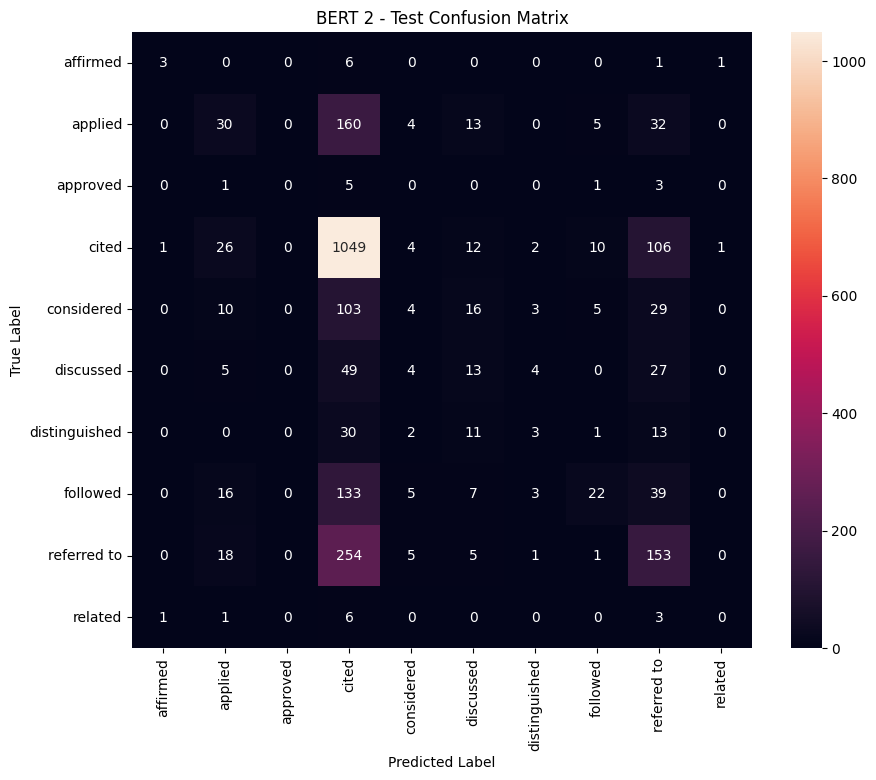

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cm_2 = confusion_matrix(
    test_true_2,
    test_predictions_2
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_2,
    annot=True,
    fmt="d",
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("BERT 2 - Test Confusion Matrix")
plt.show()

**MODEL COMPARISON**

,Model,Accuracy,Precision,Recall,Macro F1
0,Logistic Regression,0.6300,0.6300,0.3700,0.4300
1,Naive Bayes,0.5700,0.4200,0.3900,0.4000
2,Random Forest,0.5700,0.6400,0.2400,0.2900
3,BERT BASE,0.5100,0.3400,0.2200,0.2200
4,Bidirectional LSTM,0.4900,0.2200,0.1900,0.1600
5,Bidirectional GRU,0.4800,0.2300,0.1600,0.1400
6,LSTM,0.4900,0.0500,0.1000,0.0700
7,GRU,0.4900,0.0800,0.1000,0.0700
8,SimpleRNN,0.4900,0.0500,0.1000,0.0700
9,Bidirectional SimpleRNN,0.4900,0.0500,0.1000,0.0700


/tmp/ipykernel_7452/1054643256.py:99: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


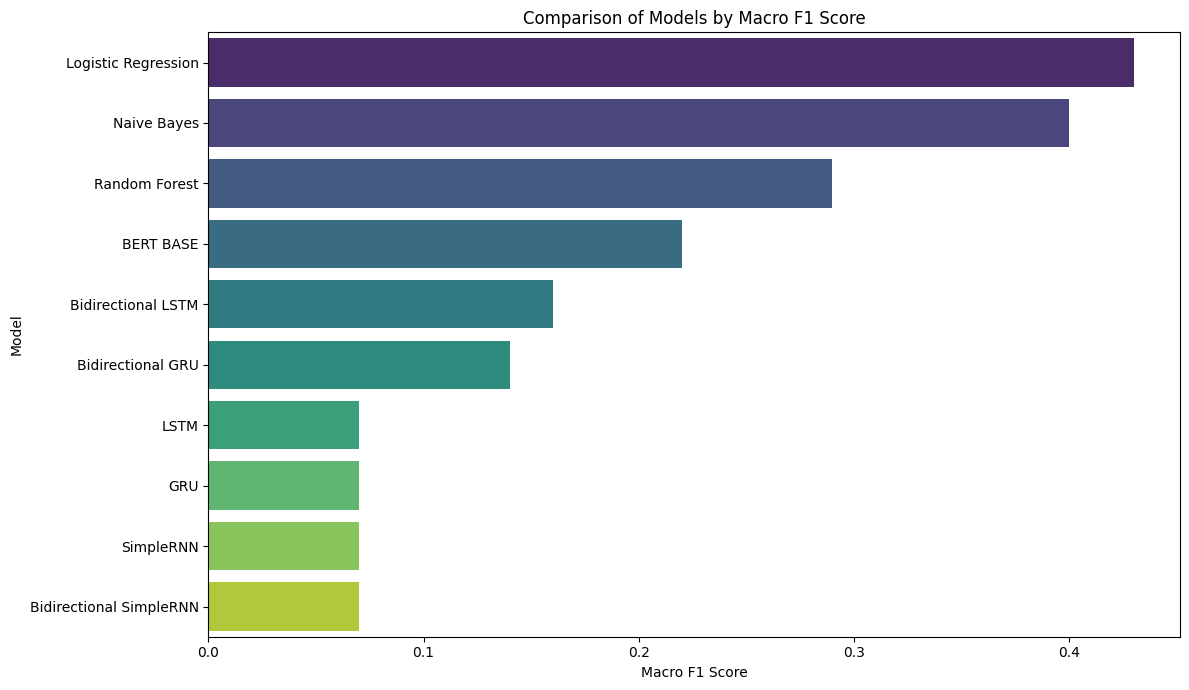

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


model_results = [
    {
        "Model": "Random Forest",
        "Accuracy": 0.5700,
        "Precision": 0.6400,
        "Recall": 0.2400,
        "Macro F1": 0.2900
    },
    {
      "Model": "Logistic Regression",
      "Accuracy": 0.6300,
      "Precision": 0.6300,
      "Recall": 0.3700,
      "Macro F1": 0.4300
    },
      {
      "Model": "Naive Bayes",
      "Accuracy": 0.5700,
      "Precision": 0.4200,
      "Recall": 0.3900,
      "Macro F1": 0.4000
    },
    {
        "Model": "SimpleRNN",
        "Accuracy": 0.4900,
        "Precision": 0.0500,
        "Recall": 0.1000,
        "Macro F1": 0.0700
    },
    {
        "Model": "GRU",
        "Accuracy": 0.4900,
        "Precision": 0.0800,
        "Recall": 0.1000,
        "Macro F1": 0.0700
    },
    {
        "Model": "LSTM",
        "Accuracy": 0.4900,
        "Precision": 0.0500,
        "Recall": 0.1000,
        "Macro F1": 0.0700
    },
    {
        "Model": "Bidirectional SimpleRNN",
        "Accuracy": 0.4900,
        "Precision": 0.0500,
        "Recall": 0.1000,
        "Macro F1": 0.0700
    },
    {
        "Model": "Bidirectional GRU",
        "Accuracy": 0.4800,
        "Precision": 0.2300,
        "Recall": 0.1600,
        "Macro F1": 0.1400
    },
    {
        "Model": "BERT BASE",
        "Accuracy": 0.5100,
        "Precision": 0.3400,
        "Recall": 0.2200,
        "Macro F1": 0.2200
    },
    {
        "Model": "Bidirectional LSTM",
        "Accuracy": 0.4900,
        "Precision": 0.2200,
        "Recall": 0.1900,
        "Macro F1": 0.1600
    }
]


comparison_df = pd.DataFrame(model_results)


comparison_df = comparison_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

display(
    comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "Macro F1": "{:.4f}"
    })
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=comparison_df,
    x="Macro F1",
    y="Model",
    palette="viridis"
)

plt.title("Comparison of Models by Macro F1 Score")
plt.xlabel("Macro F1 Score")
plt.ylabel("Model")
plt.tight_layout()
plt.show()